In [2]:
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland import analysis
from optiland import wavefront
from optiland.psf import MMDFTPSF, FFTPSF
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from scipy.special import jv
from scipy.special import j1
from torch.special import bessel_j1
from torch.special import bessel_j0
from dynesty import plotting as dyplot
from gluonts.torch.distributions import TruncatedNormal as truncnorm
import torch
from multiprocess.pool import Pool
from scipy.optimize import differential_evolution
plt.rcParams['figure.figsize'] = (20,10)
import warnings
warnings.filterwarnings('ignore')
from tqdm import tqdm
import corner

In [3]:
from poppy.zernike import zernike_basis

In [4]:
be.set_backend("torch")
be.grad_mode.enable()
be.set_precision("float64")

torch.set_default_dtype(torch.float64)

In [5]:
class bessel_jv(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, v):
        ctx.save_for_backward(x, v)
        return jv(v, x)

    @staticmethod
    def backward(ctx, grad_out):
        x, v = ctx.saved_tensors
        
        return grad_out*0.5*(bessel_jv.apply(x, v-1) -  bessel_jv.apply(x, v+1)), None

In [6]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(torch.ceil((-1 + torch.sqrt(torch.tensor(1 + 8 * j))) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(torch.floor(torch.tensor(n / 2.)))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=64, rho=None, theta=None, outside=torch.nan, zero=6, **kwargs):
 
    if theta is None and rho is None:
        x = (torch.arange(npix, dtype=torch.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = torch.meshgrid(x, y)

        rho = torch.sqrt(xx ** 2 + yy ** 2)
        theta = torch.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not torch.all(torch.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*torch.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.cos(torch.abs(torch.tensor(m) * theta))
    else:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.sin(torch.abs(torch.tensor(m) * theta))
    return cb_result.detach().clone()


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = torch.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output.detach().clone()

def decompose_psf(psf, nterms=10, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=0.0, **kwargs)
    basis_set = torch.tensor(basis_set)
    psf_flat = psf.ravel()
    basis_flat = basis_set.reshape(nterms, -1).to(torch.float64)
    numerators = torch.matmul(basis_flat, psf_flat)
    denominators = torch.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs.detach().clone()

In [7]:
def hubble(WL=0.55,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    T = 3600
    #Hubble
    hubble = optic.Optic(name="Hubble")

    hubble.add_surface(index=0, radius=np.inf, thickness=np.inf)
    hubble.add_surface(index=1, thickness=4910.01016)

    # add physical aperture in primary mirror
    obscuration = physical_apertures.RadialAperture(r_max=1200, r_min=384)
    c1 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=0, offset_y=1000)
    c2 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=-707.15, offset_y=-707.15)
    c3 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=707.15, offset_y=-707.15)
    r1 = physical_apertures.RectangularAperture(x_min=-19, x_max=19, y_min=-1200, y_max=1200)
    r2 = physical_apertures.RectangularAperture(x_min=-1200, x_max=1200, y_min=-19, y_max=19)

    ap = obscuration - r1 - r2 -c1 - c2 - c3

    hubble.add_surface(
            index=2,
            radius=-11040.02286,
            thickness=-4910.01016,
            material="mirror",
            is_stop=True,
            conic=-1.001152,
            aperture=ap,
        )
    hubble.add_surface(
            index=3,
            radius=-1349.31166,
            thickness=6365.20955+sdz/K,
            dx=sdx/K,
            dy=sdy/K,
            rx=stx/T,
            ry=sty/T,
            material="mirror",
            conic=-1.483014,
        )
    hubble.add_surface(index=4, radius=-635.38227)

    hubble.set_aperture(aperture_type="EPD", value=2400)

    hubble.set_field_type(field_type="angle")
    hubble.add_field(y=0.)
    hubble.add_field(y=0.038)
    hubble.add_field(y=-0.038)

    hubble.add_wavelength(value=WL, is_primary=True)
    
    return hubble

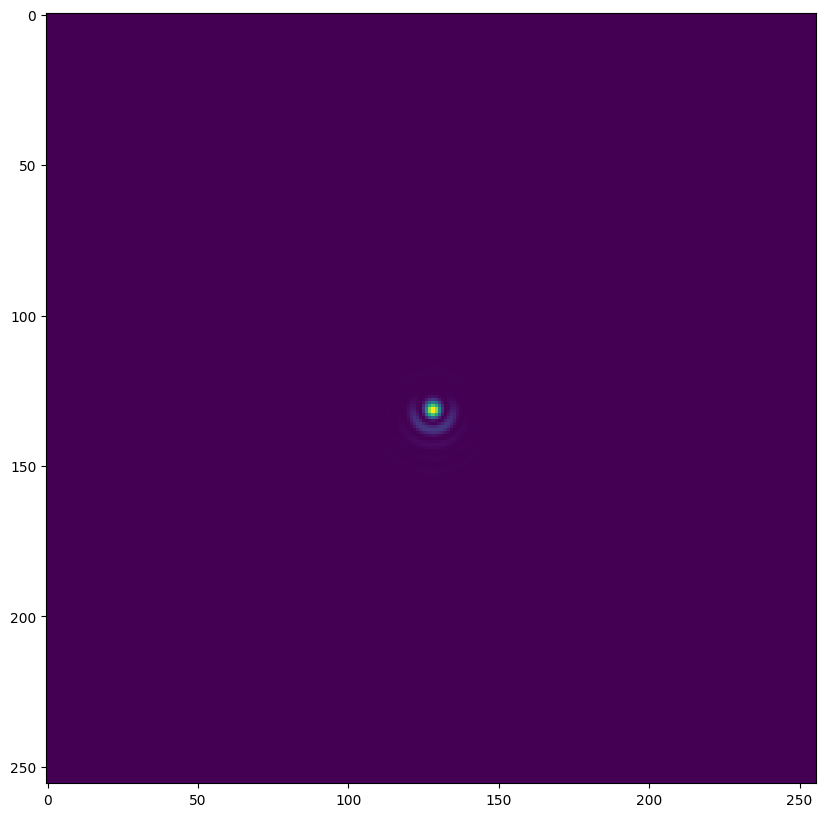

In [8]:
plt.imshow(MMDFTPSF(hubble(sdx=00, stx=1), wavelength=0.65, field=(0,0)).psf.detach().numpy())

In [11]:
def genpsf(WL=0.55, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field =(0,0)):

    telescope = hubble(WL, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, grid_size=64)
    PSF = psf.psf[96:160,96:160]
    r = decompose_psf(PSF, nterms=dterms, basis=zernike_basis)

    return r

In [24]:
xcy = []

for i in range(10000):
    x = np.round(np.random.normal(loc=0,scale=300), 2)
    y = np.round(np.random.normal(loc=0,scale=300), 2)
    z = np.round(np.random.normal(loc=0,scale=150), 2) 
    tx = np.round(np.random.normal(loc=0,scale=10), 2)
    ty = np.round(np.random.normal(loc=0,scale=10), 2)
    ars = genpsf(WL=0.55, sdx=x, sdy=y, sdz=z, stx=tx, sty=ty, dterms=15, field=(-1,-1))
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [25]:
xcy = torch.tensor(xcy)

In [26]:
torch.cov(xcy.T)

tensor([[ 2.6752e-02, -1.9947e-04,  7.0809e-04, -2.1946e-02, -2.4384e-04,
          1.8911e-04, -9.0360e-04,  4.3173e-05, -7.0769e-05,  5.7945e-06,
          1.2685e-02,  2.9137e-05,  2.1291e-04, -1.0182e-04,  5.3739e-05],
        [-1.9947e-04,  2.4932e-02, -1.7666e-04,  4.7303e-04,  2.6662e-04,
          1.2903e-04,  1.8245e-04, -1.7305e-02, -6.2714e-05, -1.2105e-04,
         -5.2042e-04, -2.5128e-04, -4.4906e-04,  6.1654e-08, -5.0010e-05],
        [ 7.0809e-04, -1.7666e-04,  2.4508e-02, -2.2469e-04,  9.4201e-05,
         -7.4690e-04, -1.7263e-02,  1.7797e-04,  3.6854e-04,  5.8813e-05,
         -2.4897e-04,  7.9732e-04, -1.7347e-04, -1.9406e-05,  9.3736e-06],
        [-2.1946e-02,  4.7303e-04, -2.2469e-04,  2.4912e-02,  1.1018e-04,
         -2.7991e-05,  6.3392e-04, -1.8567e-04,  1.6868e-05, -2.9966e-05,
         -1.8243e-02, -1.8101e-04, -9.1670e-05,  4.2642e-05, -7.1119e-05],
        [-2.4384e-04,  2.6662e-04,  9.4201e-05,  1.1018e-04,  9.9653e-03,
         -2.0368e-05,  7.4579e-05,

In [584]:
sdx_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdy_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdz_true = 0
stx_true = np.round(np.random.normal(loc=0,scale=5), 2)
sty_true = np.round(np.random.normal(loc=0,scale=5), 2)

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)

54.17 -19.62 0 6.29 0.87


In [8]:
C = torch.tensor([[ 2.8546e-02,  2.4201e-04, -3.1598e-04, -4.8934e-02, -3.2693e-04,
         -5.5986e-04, -1.0243e-03, -1.7370e-03, -4.9009e-05, -3.2011e-05,
          3.9497e-02,  9.0271e-04,  4.9170e-04,  1.0310e-04,  6.6334e-05],
        [ 2.4201e-04,  9.9158e-02, -1.7614e-03,  1.1474e-03,  2.0232e-03,
          2.0911e-03,  1.9443e-03, -9.4698e-02, -6.1838e-04,  1.3896e-05,
         -2.2020e-03, -2.8686e-03, -2.5514e-03,  1.9861e-05, -1.4131e-04],
        [-3.1598e-04, -1.7614e-03,  1.0099e-01,  2.1634e-03,  2.4404e-03,
         -2.2755e-03, -9.7984e-02,  1.9599e-03,  3.0645e-04,  2.1593e-04,
         -3.0290e-03,  2.9498e-03, -3.1703e-03, -7.1629e-05, -5.2912e-05],
        [-4.8934e-02,  1.1474e-03,  2.1634e-03,  1.0426e-01,  3.6707e-04,
          7.3733e-04,  8.9616e-04,  2.2155e-03,  3.6045e-05,  2.3623e-06,
         -9.9253e-02, -1.3523e-03, -5.8528e-04, -2.5646e-04, -9.3452e-05],
        [-3.2693e-04,  2.0232e-03,  2.4404e-03,  3.6707e-04,  3.4768e-02,
         -2.5238e-04, -1.7755e-03, -1.2087e-03,  1.0214e-03, -1.1731e-03,
         -4.0595e-05,  1.7350e-04, -3.5174e-02, -3.1900e-05,  1.4332e-04],
        [-5.5986e-04,  2.0911e-03, -2.2755e-03,  7.3733e-04, -2.5238e-04,
          3.5909e-02,  1.5078e-03, -1.4558e-03,  9.2375e-04,  1.1446e-03,
         -3.4590e-04, -3.7191e-02,  1.6025e-04,  2.9694e-04, -1.3420e-04],
        [-1.0243e-03,  1.9443e-03, -9.7984e-02,  8.9616e-04, -1.7755e-03,
          1.5078e-03,  1.1243e-01, -2.1993e-03, -1.7086e-04, -3.8854e-04,
          5.2096e-04, -2.7584e-03,  3.1177e-03,  7.1545e-05,  5.9634e-05],
        [-1.7370e-03, -9.4698e-02,  1.9599e-03,  2.2155e-03, -1.2087e-03,
         -1.4558e-03, -2.1993e-03,  1.0681e-01,  6.0168e-04, -8.2099e-05,
         -6.8326e-04,  2.7540e-03,  2.2908e-03, -3.5036e-05,  1.4671e-04],
        [-4.9009e-05, -6.1838e-04,  3.0645e-04,  3.6045e-05,  1.0214e-03,
          9.2375e-04, -1.7086e-04,  6.0168e-04,  9.0955e-03, -1.2108e-04,
          1.7585e-05, -7.1916e-04, -8.8275e-04, -3.6350e-04,  3.9637e-04],
        [-3.2011e-05,  1.3896e-05,  2.1593e-04,  2.3623e-06, -1.1731e-03,
          1.1446e-03, -3.8854e-04, -8.2099e-05, -1.2108e-04,  9.4166e-03,
          5.8236e-06, -1.0284e-03,  1.0278e-03,  3.9824e-04,  3.7200e-04],
        [ 3.9497e-02, -2.2020e-03, -3.0290e-03, -9.9253e-02, -4.0595e-05,
         -3.4590e-04,  5.2096e-04, -6.8326e-04,  1.7585e-05,  5.8236e-06,
          1.0623e-01,  6.7788e-04,  1.9345e-04,  2.4776e-04,  5.0283e-05],
        [ 9.0271e-04, -2.8686e-03,  2.9498e-03, -1.3523e-03,  1.7350e-04,
         -3.7191e-02, -2.7584e-03,  2.7540e-03, -7.1916e-04, -1.0284e-03,
          6.7788e-04,  4.3718e-02, -1.6952e-04, -2.9792e-04,  1.8890e-04],
        [ 4.9170e-04, -2.5514e-03, -3.1703e-03, -5.8528e-04, -3.5174e-02,
          1.6025e-04,  3.1177e-03,  2.2908e-03, -8.8275e-04,  1.0278e-03,
          1.9345e-04, -1.6952e-04,  4.0530e-02, -2.1973e-06, -1.8618e-04],
        [ 1.0310e-04,  1.9861e-05, -7.1629e-05, -2.5646e-04, -3.1900e-05,
          2.9694e-04,  7.1545e-05, -3.5036e-05, -3.6350e-04,  3.9824e-04,
          2.4776e-04, -2.9792e-04, -2.1973e-06,  1.0394e-03,  1.3562e-05],
        [ 6.6334e-05, -1.4131e-04, -5.2912e-05, -9.3452e-05,  1.4332e-04,
         -1.3420e-04,  5.9634e-05,  1.4671e-04,  3.9637e-04,  3.7200e-04,
          5.0283e-05,  1.8890e-04, -1.8618e-04,  1.3562e-05,  9.7441e-04]])
Cinv = torch.linalg.inv(C).to(torch.float64)  # precision matrix
lnorm = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    lsdx,lsdy,lstx,lsty = theta
    ## PSF
    c = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, stx=lstx, sty=lsty, dterms=15)

    return -0.5 * torch.matmul(torch.tensor(c-ct), torch.matmul(Cinv, torch.tensor(c-ct))) + lnorm

# prior transform
def ptform(utheta):

    usx,usy,ustx,usty = utheta

    xsx =  np.round((500. * (2. * usx - 1.)), decimals=2)
    xsy =  np.round((500. * (2. * usy - 1.)), decimals=2)
    #xsz =  np.round((100. * (2. * usz - 1.)), decimals=2)
    xstx =  np.round((10. * (2. * ustx - 1.)), decimals=2)
    xsty =  np.round((10. * (2. * usty - 1.)), decimals=2)
    """msx, ssx = torch.tensor(0), torch.tensor(10)  # mean and standard deviation
    lsx, hsx = torch.tensor(-100), torch.tensor(100)  # lower and upper bounds
    xsx = truncnorm(min=lsx, max=hsx, loc=msx, scale=ssx).icdf(torch.tensor(usx))

    msy, ssy = torch.tensor(0), torch.tensor(10)  # mean and standard deviation
    lsy, hsy = torch.tensor(-100), torch.tensor(100)  # lower and upper bounds
    xsy = truncnorm(min=lsy, max=hsy, loc=msy, scale=ssy).icdf(torch.tensor(usy))

    msz, ssz = torch.tensor(0), torch.tensor(20)  # mean and standard deviation
    lsz, hsz = torch.tensor(-300), torch.tensor(300)  # lower and upper bounds
    xsz = truncnorm(min=lsz, max=hsz, loc=msz, scale=ssz).icdf(torch.tensor(usz))

    mstx, sstx = torch.tensor(0), torch.tensor(3)  # mean and standard deviation
    lstx, hstx = torch.tensor(-6), torch.tensor(6)  # lower and upper bounds
    xstx = truncnorm(min=lstx, max=hstx, loc=mstx, scale=sstx).icdf(torch.tensor(ustx))

    msty, ssty = torch.tensor(0), torch.tensor(3)  # mean and standard deviation
    lsty, hsty = torch.tensor(-6), torch.tensor(6)  # lower and upper bounds
    xsty = truncnorm(min=lsty, max=hsty, loc=msty, scale=ssty).icdf(torch.tensor(usty))"""

    return xsx,xsy,xstx,xsty

In [71]:
@numba.jit
def Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=5, K = 500, iter=1000):
    stopping_criterion = 10E-5#+10E-3*(K-1)
    dps = []
    ls = [] 
    PVAL = 1
    Z = 0
    lps_init = torch.rand(ndim, K)
    lps = prior(lps_init)
    lps = torch.stack(list(lps), dim=0)
    lps = lps.transpose(-1,0)
    lps_eval = torch.zeros(K)
    pbar1 = tqdm(total = K)
    for i in range(K):
        lps_eval[i] = loglike(lps[i])
        pbar1.update(1)
    pbar1.close()
    
    minl = torch.min(lps_eval, 0)[0]
    n_it = 1
    dlogz = 0.1

    pbar2 = tqdm(total = n_it+1)
    while n_it < iter+1:
        minl = torch.min(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        nlp = prior(torch.rand(ndim,1))
        nlp = torch.stack(list(nlp), dim=0)
        nlike = likelihood(nlp)
        #z = (minl)*(-1/K)
        if nlike > minl:
            dps.append(dp1)
            ls.append(minl)
            lps = lps[lps!=dp1]
            lps = lps.reshape(K-1, ndim)
            lps_eval = lps_eval[lps_eval!=minl]
            nlp = nlp.reshape(1, ndim)
            lps = torch.cat((lps, nlp))
            nlike = nlike.reshape(1)
            lps_eval = torch.cat((lps_eval, nlike))
            dz = PVAL*torch.max(lps_eval)
            PVAL -= K/(K+1)
            #wi = (torch.exp(torch.tensor(-(n_it-1)/K))-torch.exp(torch.tensor(-(n_it+1)/K)))/2
            Z += dz
            dlogz = torch.log(Z + dz) - torch.log(Z)
            pbar2.update(1)
            pbar2.set_postfix({'dlogz': dlogz, 'logl': nlike})
            #print(f"dlogz = {dlogz}, niter = {n_it}")
            n_it += 1 
           
    for n_it in range(n_it,n_it+K-1):
        minl = torch.min(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        dps.append(dp1)
        ls.append(minl)
        lps = lps[lps!=dp1]
        lps = lps.reshape(K-1, ndim)
        lps_eval = lps_eval[lps_eval!=minl]
        #dz = PVAL*torch.max(lps_eval)
        #PVAL = PVAL - 1/K
        #z = (minl)*(-1/K)
        #dlogz = torch.log(z + dz) - torch.log(z)
        #print(f"dp1 = {dp1}")
        pbar2.update(1)
        #print(f"minl = {minl}, n_it = {n_it}")
        K = K-1
        n_it += 1
    pbar2.close() 

    return dps, ls

In [11]:
from nautilus import Sampler

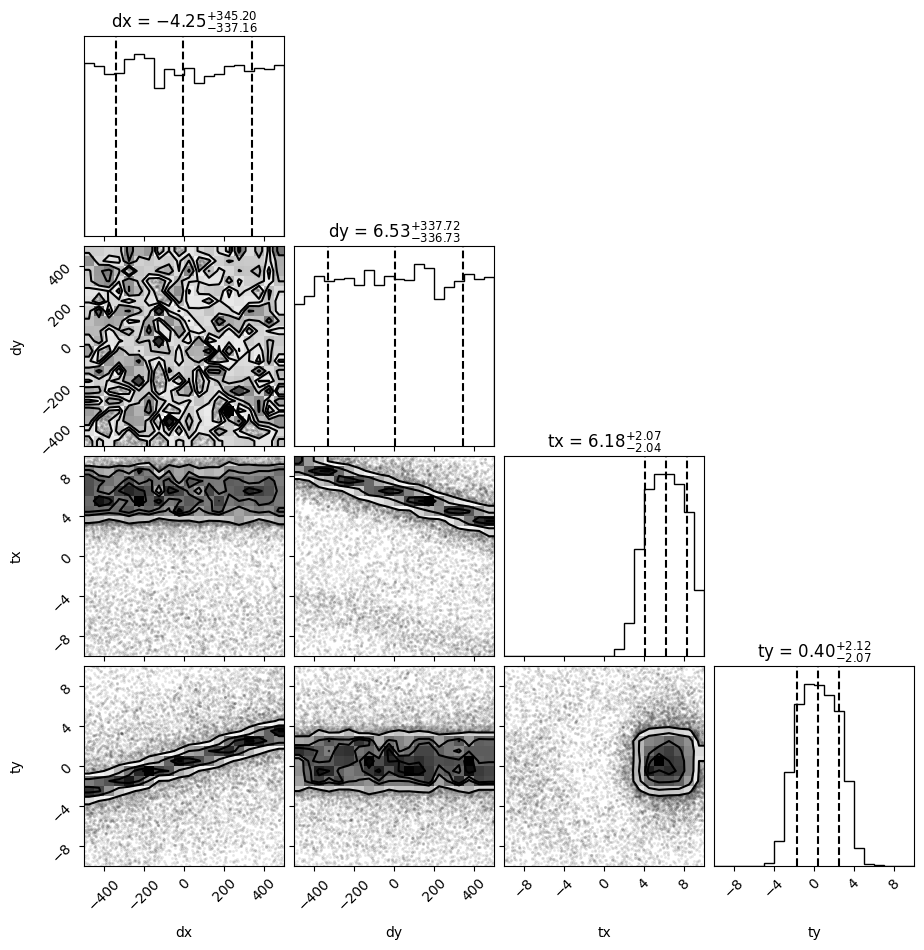

In [587]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['dx', 'dy', 'tx', 'ty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

In [588]:
print(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

62.09 37.71 5.87 0.99


In [589]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

54.17 -19.62 0 6.29 0.87


In [590]:
sdx_true = 54.17 
sdy_true = -19.62 
sdz_true = 0
stx_true = 6.29 
sty_true = 0.87+1

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)

54.17 -19.62 0 6.29 1.87


In [591]:
sampler = Sampler(ptform, loglike, n_dim=4)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 13     | 1        | 4        | 28600    | N/A    | 12563 | +25.03   


np.True_

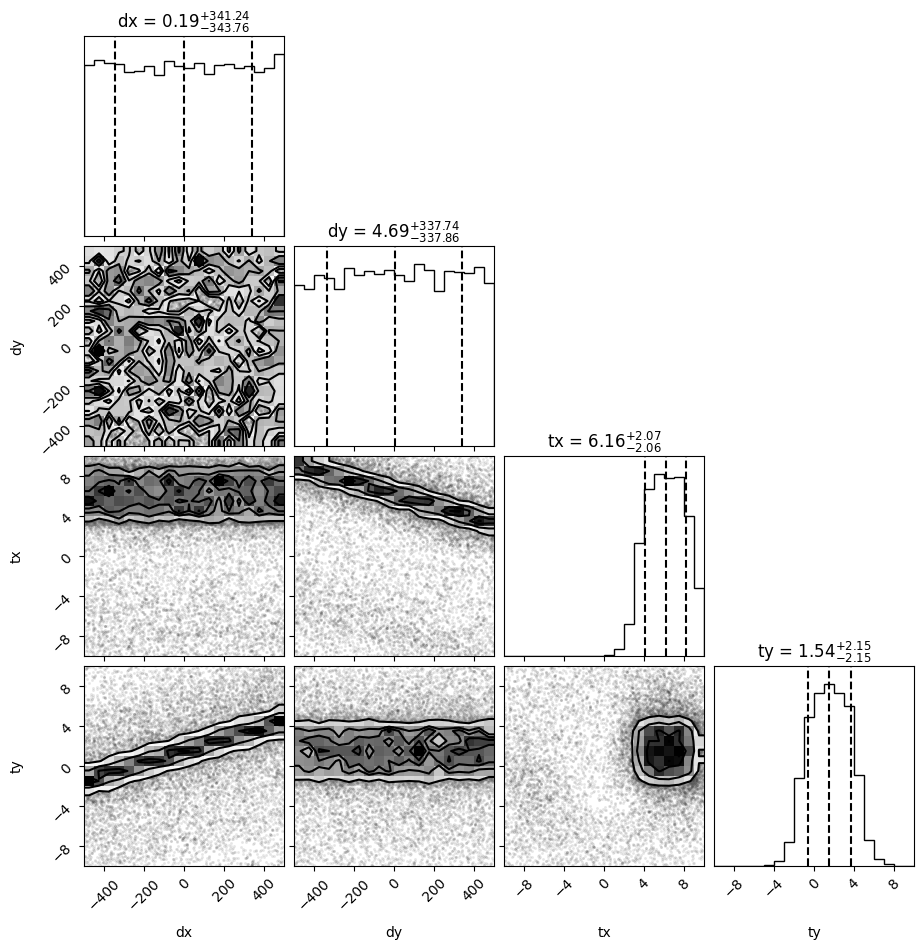

In [592]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['dx', 'dy', 'tx', 'ty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

In [593]:
print(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

-89.43 20.72 5.97 1.05


In [594]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

54.17 -19.62 0 6.29 1.87


In [12]:
#Truth

sdx_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdy_true = np.round(np.random.normal(loc=0,scale=50), 2)
stx_true = np.round(np.random.normal(loc=0,scale=3), 2)
sty_true = np.round(np.random.normal(loc=0,scale=3), 2)

## PSF 
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, stx=stx_true, sty=sty_true, dterms=15)

it = 0
n_it  = 2

while it<n_it:
    
    sampler = Sampler(ptform, loglike, n_dim=4)
    sampler.run(verbose=True)
    points, log_w, log_l = sampler.posterior()

    wts = np.exp(log_w)

    print(sdx_true, sdy_true, stx_true, sty_true)

    print(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

    sdx_true -= np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    sdy_true -= np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    stx_true -= np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    sty_true -= np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    ## PSF 
    ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, stx=stx_true, sty=sty_true, dterms=15)

    it += 1

def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], stx=t[2], sty=t[3], dterms=15))**2)

bounds = [(np.quantile(points[-100:,0], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]
          
result = differential_evolution(lstep, bounds, disp=True, maxiter=1000)
print(sdx_true, sdy_true, stx_true, sty_true)
print(result.x)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 16     | 1        | 4        | 34800    | N/A    | 14238 | +23.07   
-12.93 108.67 2.09 -0.29
-48.4 -29.18 2.89 -0.53
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 16     | 1        | 4        | 36900    | N/A    | 10285 | +22.57   
35.47 137.85 -0.8000000000000003 0.24000000000000005
-11.86 22.17 -0.1 -0.06
differential_evolution step 1: f(x)= 0.05931352485561408
differential_evolution step 2: f(x)= 0.006011786597276738
differential_evolution step 3: f(x)= 0.006011786597276738
differential_evolution step 4: f(x)= 0.0019270702755393746
differential_evolution step 5: f(x)= 0.0019270702755393746
differential_evolution step 6: f(x)= 0.0019270702755393746
differential_evoluti

In [ ]:
-12.93 108.67 2.09 -0.29
-48.4 -29.18 2.89 -0.53
35.47 137.85 -0.8000000000000003 0.24000000000000005
-11.86 22.17 -0.1 -0.06
47.33 115.67999999999999 -0.7000000000000003 0.30000000000000004
47.34436956 115.67466186  -0.69996833   0.30008525

-42.09 40.99 2.7 1.79
-63.12 -76.97 3.49 1.73                                                                                                
21.029999999999994 117.96000000000001 -0.79 0.06000000000000005
-44.38 -37.23 0.1 -0.33
65.41 155.19 -0.89 0.39000000000000007
65.41185325 155.18884918  -0.88999317   0.39001099

43.14 78.62 -1.4 -1.16
5.03 5.03 -0.98 -1.36
38.11 73.59 -0.41999999999999993 0.20000000000000018
-106.71 -23.73 0.15 -0.66
144.82 97.32000000000001 -0.57 0.8600000000000002
144.90629745  97.18891459  -0.56922229   0.86051199

In [565]:
print(np.quantile(points[-100:,0], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.16, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

-145.36 -44.96 -4.3 -4.88


In [566]:
print(np.quantile(points[-100:,0], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.84, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

342.28 363.73 -1.87 -1.98


In [547]:
def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], stx=t[2], sty=t[3], dterms=50))**2)

In [548]:
bounds = [(-6.65-330.72,-6.65+347.78), (0.87-338.60,0.87+337.13), (-2.15-2, -2.15+2.01), (-4.04-1.97, -4.04+2.06)]
result = differential_evolution(lstep, bounds, tol=0.001, disp=True, maxiter=1000)

differential_evolution step 1: f(x)= 0.0030980763692943273
differential_evolution step 2: f(x)= 0.0030980763692943273
differential_evolution step 3: f(x)= 0.0015551917924476087
differential_evolution step 4: f(x)= 0.0015551917924476087
differential_evolution step 5: f(x)= 0.0015551917924476087
differential_evolution step 6: f(x)= 8.050681038633936e-05
differential_evolution step 7: f(x)= 8.050681038633936e-05
differential_evolution step 8: f(x)= 8.050681038633936e-05
differential_evolution step 9: f(x)= 8.050681038633936e-05
differential_evolution step 10: f(x)= 8.050681038633936e-05
differential_evolution step 11: f(x)= 3.110132517480976e-05
differential_evolution step 12: f(x)= 3.110132517480976e-05
differential_evolution step 13: f(x)= 3.110132517480976e-05
differential_evolution step 14: f(x)= 3.110132517480976e-05
differential_evolution step 15: f(x)= 3.110132517480976e-05
differential_evolution step 16: f(x)= 3.110132517480976e-05
differential_evolution step 17: f(x)= 2.388871063

In [550]:
result.x

array([123.99940654, 244.99968057,  -3.58999811,  -3.27000352])

In [421]:
sdx_true = -4.12
sdy_true =  28.59
#sdz_true -=np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf') 
stx_true = 0.01
sty_true = 0.01

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=50)

-4.12 28.59 0 0.01 0.01


In [422]:
C = torch.cov(xcy.T)
Cinv = torch.linalg.inv(C).to(torch.float64)  # precision matrix
lnorm = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 2 + torch.log(torch.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    lsdx,lsdy = theta
    ## PSF
    c = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, dterms=50)

    return -0.5 * torch.matmul(torch.tensor(c-ct), torch.matmul(Cinv, torch.tensor(c-ct))) + lnorm

# prior transform
def ptform(utheta):

    usx,usy = utheta

    xsx =  50. * (2. * usx - 1.)
    xsy =  50. * (2. * usy - 1.)

    return xsx,xsy

In [73]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=2, K = 500, iter=1000)

dps = np.array(dps) 
ls = np.array(ls)

wts = (ls - ls.min())/(ls.max() - ls.min())

TypingError: Failed in nopython mode pipeline (step: nopython frontend)
Untyped global name 'tqdm': Cannot determine Numba type of <class 'type'>

File "../../../../../../var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_1614/470475590.py", line 13:
<source missing, REPL/exec in use?>

During: Pass nopython_type_inference 

This error may have been caused by the following argument(s):
- argument 0: Cannot determine Numba type of <class 'function'>
- argument 1: Cannot determine Numba type of <class 'function'> 

This error may have been caused by the following argument(s):
- argument 0: Cannot determine Numba type of <class 'function'>
- argument 1: Cannot determine Numba type of <class 'function'>


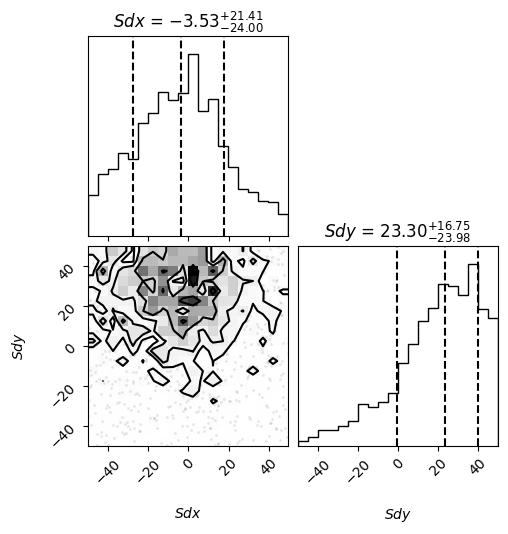

In [424]:
figure = corner.corner(
    dps,
    labels=[
        r"$Sdx$",
        r"$Sdy$",
    ],
    quantiles=[0.16, 0.5, 0.84],
    weights = wts,
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [425]:
print(np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf'),
      np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf')) 

-4.677019444491892 30.169356572454674


In [426]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

-4.12 28.59 0 0.01 0.01


In [ ]:
sdx_true -= np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
sdy_true -= np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=11)

1.4861177186653336 -0.5768106595629288 0 0 0.01


In [266]:
def ptform(utheta):

    usdx,usdy = utheta

    xsdx =  5. * (2. * usdx - 1.)
    xsdy =  5. * (2. * usdy - 1.)

    return xsdx,xsdy

In [267]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=2, K = 500, iter=1000)

dps = np.array(dps) 
ls = np.array(ls)

wts = (ls - ls.min())/(ls.max() - ls.min())

100%|██████████| 500/500 [00:14<00:00, 34.79it/s]
1499it [01:34, 15.88it/s, dlogz=tensor(nan), logl=tensor([19.2360])]                       


In [268]:
print(np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf'),
      np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf')) 

-0.12883049905774602 -0.5574719142346174


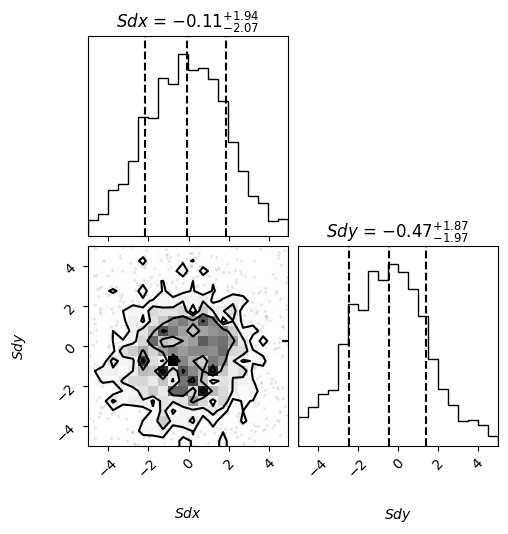

In [269]:
figure = corner.corner(
    dps,
    labels=[
        r"$Sdx$",
        r"$Sdy$",
    ],
    quantiles=[0.16, 0.5, 0.84],
    weights = wts,
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [270]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

1.4861177186653336 -0.5768106595629288 0 0 0.01


In [271]:
sdx_true -= np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf')
sdy_true -= np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf')

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=11)

1.6149482177230796 -0.01933874532831137 0 0 0.01


In [272]:
def ptform(utheta):

    usdx,usdy = utheta

    xsdx =  2. * (2. * usdx - 1.)
    xsdy =  2. * (2. * usdy - 1.)

    return xsdx,xsdy

In [274]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=2, K = 500, iter=1000)

dps = np.array(dps)
ls = np.array(ls)

wts = (ls - ls.min())/(ls.max() - ls.min())

100%|██████████| 500/500 [00:15<00:00, 32.82it/s]
1499it [01:32, 16.17it/s, dlogz=tensor(nan), logl=tensor([19.2369])]                       


In [275]:
print(np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf'),
      np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf')) 

-0.007350941867474425 -0.04679434278123695


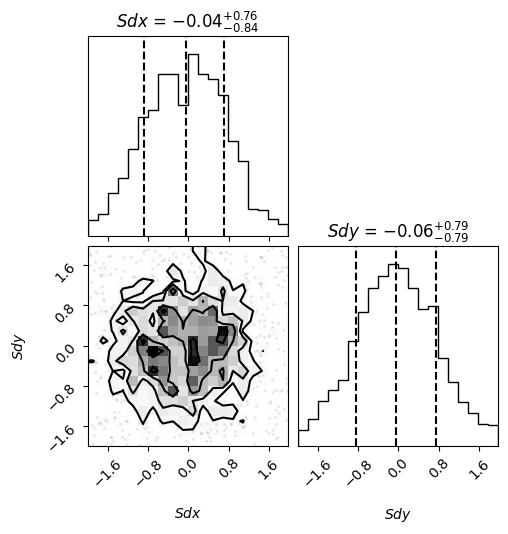

In [276]:
figure = corner.corner(
    dps,
    labels=[
        r"$Sdx$",
        r"$Sdy$",
    ],
    quantiles=[0.16, 0.5, 0.84],
    weights = wts,
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [277]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

1.6149482177230796 -0.01933874532831137 0 0 0.01


In [512]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=3, K = 500, iter=1000)

dps = np.array(dps)
ls = np.array(ls)

wts = (ls - ls.min())/(ls.max() - ls.min())

100%|██████████| 500/500 [00:25<00:00, 19.61it/s]
1499it [02:52,  8.67it/s, dlogz=tensor(nan), logl=tensor([80.3727])]                       


In [514]:
print(np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf'),np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf'),np.quantile(dps[1000:,2], 0.5, weights=wts[1000:], method='inverted_cdf')) 

15.389492863251641 -51.01619223062701 -9.68581768282335


In [ ]:
def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], sdz=t[2], stx=t[3], sty=t[4], dterms=15))**2)

In [516]:
minimize(lstep, [15.389492863251641,-51.01619223062701,-9.68581768282335,0,0], method='Nelder-Mead')

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 6.048938534342183e-13
             x: [ 1.838e+01 -4.190e+01 -4.971e-02  2.006e-03  2.457e-03]
           nit: 191
          nfev: 339
 final_simplex: (array([[ 1.838e+01, -4.190e+01, ...,  2.006e-03,
                         2.457e-03],
                       [ 1.838e+01, -4.190e+01, ...,  2.006e-03,
                         2.457e-03],
                       ...,
                       [ 1.838e+01, -4.190e+01, ...,  2.006e-03,
                         2.457e-03],
                       [ 1.838e+01, -4.190e+01, ...,  2.006e-03,
                         2.457e-03]]), array([ 6.049e-13,  6.049e-13,  6.049e-13,  6.049e-13,
                        6.049e-13,  6.049e-13]))

In [462]:
from nautilus import Sampler

sampler = Sampler(ptform, loglike, n_dim=2)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 8      | 1        | 4        | 18100    | N/A    | 10139 | +80.62   


np.True_

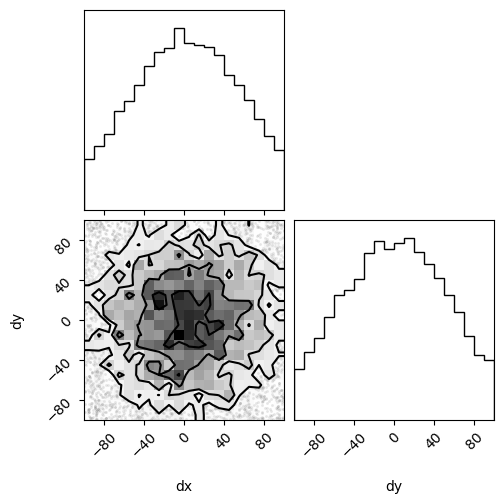

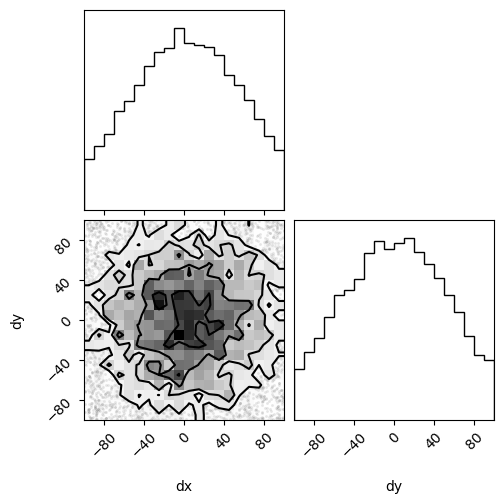

In [ ]:
import corner
import matplotlib.pyplot as plt
 
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['dx', 'dy', 'tx', 'ty'])

In [486]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=2, K = 500, iter=2000)

dps = np.array(dps)
ls = np.array(ls)

wts = (ls - ls.min())/(ls.max() - ls.min())

100%|██████████| 500/500 [00:26<00:00, 19.12it/s]
2499it [24:48,  1.68it/s, dlogz=tensor(nan), logl=tensor([81.3535])]                       


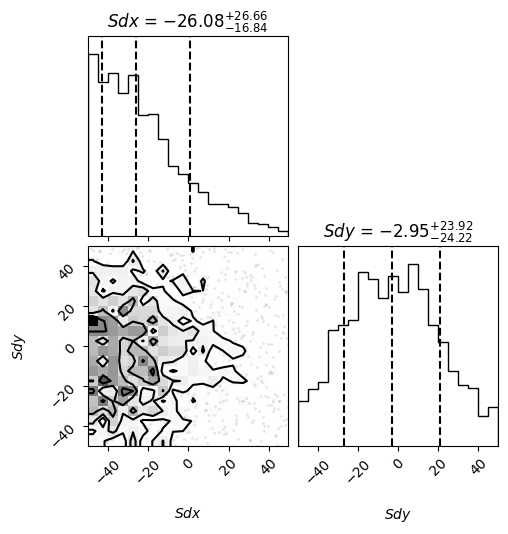

In [560]:
figure = corner.corner(
    dps,
    labels=[
        r"$Sdx$",
        r"$Sdy$",
    ],
    quantiles=[0.16, 0.5, 0.84],
    weights = wts,
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [ ]:

print(np.quantile(dps[1000:,0], 0.5, weights=wts[1000:], method='inverted_cdf'),np.quantile(dps[1000:,1], 0.5, weights=wts[1000:], method='inverted_cdf'))

-0.580834879611225 -0.23318033684598394


In [485]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

10.974961892938175 -0.3253994584427975 0 0.00540242217765563 0.06764862143058537


In [498]:
def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], stx=t[2], sty=t[3], dterms=15))**2)

In [499]:
minimize(lstep, [-0.580834879611225,-0.23318033684598394,0.00540242217765563,0.06764862143058537], method='Powell')

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 6.630464285565528e-11
       x: [-4.199e+02 -4.130e+02 -1.080e-03 -1.765e-01]
     nit: 3
   direc: [[ 1.000e+00  0.000e+00  0.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00  0.000e+00  1.000e+00]
           [ 0.000e+00  0.000e+00  1.000e+00  0.000e+00]
           [-3.167e-04 -2.551e-01  4.978e-06 -2.767e-04]]
    nfev: 193

In [467]:
    print(np.median(points[:,0]),
          np.median(points[:,1]))

4.322004969396209 2.5352003996167327


In [439]:
points[-2]

array([-5.84507651, 13.39165635])

In [232]:
    print(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,4], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

-98.48743020579396 -96.4575098739848 -295.077394760811 -4.440604759408506 -5.55473117284576


In [192]:
np.quantile(points[-500:,4], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')

array(0.4733842)

In [186]:
points[-1]

array([ -6.4442452 ,  -8.29870478, -20.02381665,  -1.35881323,
         0.43936584])

In [ ]:
#Truth

sdx_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdy_true = np.round(np.random.normal(loc=0,scale=50), 2)
stx_true = np.round(np.random.normal(loc=0,scale=3), 2)
sty_true = np.round(np.random.normal(loc=0,scale=3), 2)

## PSF 
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, stx=stx_true, sty=sty_true, dterms=15)

it = 0
n_it  = 2

while it<n_it:
    
    sampler = Sampler(ptform, loglike, n_dim=4)
    sampler.run(verbose=True)
    points, log_w, log_l = sampler.posterior()

    wts = np.exp(log_w)

    print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

    print(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
          np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))

    sdx_true -= np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    sdy_true -= np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    stx_true -= np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    sty_true -= np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')
    ## PSF 
    ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, stx=stx_true, sty=sty_true, dterms=15)

    it += 1



Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 36500    | N/A    | 10951 | +22.42   
34.65 -95.65 0 -0.96 -0.58
-105.75 -102.34 -0.91 -1.38
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 37300    | N/A    | 10611 | +22.60   
140.4 6.689999999999998 0 -0.04999999999999993 0.7999999999999999
142.02 1.22 -0.03 0.84
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 36800    | N/A    | 10325 | +22.59   
-1.6200000000000045 5.469999999999998 0 -0.019999999999999934 -0.040000000000000036
-132.23 -40.94 0

In [223]:
## PSF 
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)

it = 0
n_it  = 5

while it<n_it:
    
    sampler = Sampler(ptform, loglike, n_dim=5)
    sampler.run(verbose=True, timeout=12000)
    points, log_w, log_l = sampler.posterior()

    wts = np.exp(log_w)

    print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

    print(np.quantile(points[-500:,0], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf'),
          np.quantile(points[-500:,1], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf'),
          np.quantile(points[-500:,2], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf'),
          np.quantile(points[-500:,3], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf'),
          np.quantile(points[-500:,4], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf'))

    sdx_true -= np.quantile(points[-500:,0], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')
    sdy_true -= np.quantile(points[-500:,1], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')
    sdz_true -= np.quantile(points[-500:,2], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')
    stx_true -= np.quantile(points[-500:,3], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')
    sty_true -= np.quantile(points[-500:,4], 0.5, weights=np.exp(log_w)[-500:], method='inverted_cdf')
    ## PSF 
    ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)

    it += 1

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 25     | 1        | 4        | 67400    | N/A    | 10041 | +14.18   
13.892709088195424 13.623875659861216 -1.3090112296852403 -0.08052109963901749 0.08216587525712249
0.034383907161717964 -0.6593644115808234 1.9704829697038737 0.004223375395600972 0.0001042386936885347
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 25     | 1        | 4        | 72400    | N/A    | 10016 | +14.19   
13.858325181033706 14.283240071442039 -3.279494199389114 -0.08474447503461846 0.08206163656343396
0.5133220608579494 0.6999794098861646 1.9209821055361986 -0.003926549370050186 0.0021321636515864175
Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Statu

In [73]:
dxtx = [[63.95, -3.41],
[53.11647002556719, 0.1429637342707606],
[5.670535232618121, -0.008016043384180466],
[17.9369230736167, -0.006658799266686249],      
[13.60097575887826, 0.0015269628681024864]]

In [ ]:
#Truth

sdx_true = np.round(np.random.normal(loc=0,scale=500), 2)
sdy_true = np.round(np.random.normal(loc=0,scale=500), 2)
sdz_true = 0 #np.round(np.random.normal(loc=0,scale=1500), 2)
stx_true = np.round(np.random.normal(loc=0,scale=30), 2)
sty_true = np.round(np.random.normal(loc=0,scale=30), 2)

## PSF 
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=10)

it = 0
n_it  = 10

while it<n_it:
    dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=4, K = 500, iter=5000)

    dps = np.array(dps)
    ls = np.array(ls)

    wts = (ls - ls.min())/(ls.max() - ls.min())

    print(sdx_true, sdy_true, stx_true, sty_true)

    print(np.quantile(dps[5000:,0], 0.5, weights=wts[5000:], method='inverted_cdf'),np.quantile(dps[5000:,1], 0.5, weights=wts[5000:], method='inverted_cdf'),np.quantile(dps[5000:,2], 0.5, weights=wts[5000:], method='inverted_cdf'), np.quantile(dps[5000:,3], 0.5, weights=wts[5000:], method='inverted_cdf'))

    sdx_true -= np.quantile(dps[5000:,0], 0.5, weights=wts[5000:], method='inverted_cdf')
    sdy_true -= np.quantile(dps[5000:,1], 0.5, weights=wts[5000:], method='inverted_cdf')
    #sdz_true -= np.quantile(dps[5000:,2], 0.5, weights=wts[5000:], method='inverted_cdf')
    stx_true -= np.quantile(dps[5000:,2], 0.5, weights=wts[5000:], method='inverted_cdf')
    sty_true -= np.quantile(dps[5000:,3], 0.5, weights=wts[5000:], method='inverted_cdf')
    ## PSF 
    ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, stx=stx_true, sty=sty_true, dterms=10)

    it += 1

100%|██████████| 500/500 [00:34<00:00, 14.36it/s]
1499it [03:38,  6.87it/s, dlogz=tensor(nan), logl=tensor([17.2472])]                       


696.39 85.16 36.09 -24.2
-42.48041615663558 21.7079358871095 6.3415589024894095 0.34436088623710975


100%|██████████| 500/500 [00:34<00:00, 14.51it/s]
1499it [03:30,  7.12it/s, dlogz=tensor(nan), logl=tensor([17.2382])]                       


738.8704161566355 63.4520641128905 29.748441097510593 -24.544360886237108
-3.212496413381753 5.83505923415527 5.241770878176736 -2.682317874217352


100%|██████████| 500/500 [00:33<00:00, 14.78it/s]
1499it [03:08,  7.97it/s, dlogz=tensor(nan), logl=tensor([17.2294])]                       


742.0829125700172 57.61700487873523 24.506670219333856 -21.862043012019754
-11.058246842604563 -15.013248000638084 1.6095934481946208 2.4868226806511924


In [354]:
xt = [[-141.28, 785.78, -1937.62, -18.04, 5.03],
[-138.06357827695118, 820.9337348476978, -2032.4351631676802, -2.920875971433748 , 5.47207561326276],
[-120.48440412645978, 780.3516115620598, -1877.8543477409348, -4.6659233601347285, 4.02645694538781],
[-147.43461761430558, 774.5462656490719, -1882.5286588648457, -3.559841603869602 , 3.40181244127680],
[-161.66577444327456, 742.4488975196493, -1800.6451938272294, -3.5843387003672067, 4.47439791375517],
[-166.7389000151837 , 774.7879753506282, -1655.439457179574 , -5.466431044001157 , 0.41946849694704],
[-166.10387569579808, 818.1403305332414, -1567.6064703299849, -5.247229348714858 , 0.42048554408025],
[-203.410100377318  , 749.8941316186622, -1649.8019759462077, -4.698061405828066 , -0.5668810949580],
[-204.67512560179574, 749.7163716458928, -1526.0949278388746, -9.885566484589736 , -0.7943047408299],
[-221.45664599213166, 713.132888016253 , -1513.2752976753272, -1.5843946827450015, -1.3137040957486],
[-238.3107206807805 , 690.8649053545148, -1544.365038373105 , -7.293221433419755 , -2.1214886742418],
[-220.32115573237186, 699.7793012880243, -1536.7249659307415, 0.27123828898738633, -1.9712365377582],
[-243.75852161870992, 703.7484684171876, -1483.327763820857 , -6.629653997136045 , -2.7486630308884],
[-300.7709470235236 , 706.6462344697553, -1387.0901030773027, -1.4461088302733813, -3.5266252230109],
[-337.1163882238542 , 740.1865711323745, -1241.4943544853575, -6.240001615299393 , -3.9316458688918],
[-373.7167759609123 , 717.3809855478797, -1098.1043524928455, -2.380479449752601 , -4.0183732099231],
[-363.02371167166604, 703.555485294283 , -996.4251076842111 , -6.12475495007839  , -4.1422735750428],
[-340.39191469513923, 688.2654351251689, -820.6673796229175 , -1.86969192709505  , -4.5602273260352],
[-361.3497571955231 , 695.8219728651723, -760.7960266824564 , -5.111682578019469 , -5.2801399061650],
[-439.389173095636  , 723.5944425060209, -656.7313059887299 , -3.6708773856075325, -5.8737215318898]]


"""-3.216421723048819 -35.153734847697784 94.81516316768037 -15.119124028566251 -0.4420756132627625
-17.5791741504914 40.582123285637984 -154.58081542674552 1.74504738870098 1.445618667874945
26.950213487845794 5.805345912987903 4.674311123910847 -1.1060817562651266 0.62464450411101
14.231156828968972 32.097368129422534 -81.88346503761625 0.024497096497604575 -1.0725854724783659
5.073125571909145 -32.33907783097896 -145.2057366476554 1.8820923436339507 4.0549294168081245
-0.6350243193856256 -43.352355182613124 -87.83298684958905 -0.21920169528629962 -0.0010170471332108934
37.30622468151992 68.24619891457914 82.1955056162228 -0.5491679428867916 0.9873666390383494
1.2650252244777336 0.1777599727694057 -123.70704810733305 5.18750507876167 0.2274236458718104
16.781520390335928 36.58348362963974 -12.819630163547437 -8.301171801844735 0.5193993549187601
16.85407468864885 22.267982661738195 31.089740697777902 5.708826750674754 0.8077845784931532
-17.989564948408624 -8.914395933509521 -7.640072442363647 -7.5644597224071415 -0.15025213648352986
23.437365886338068 -3.9691671291633144 -53.397202109884525 6.900892286123431 0.7774264931302005
57.01242540481367 -2.8977660525676474 -96.23766074355413 -5.183545166862664 0.7779621921224866
36.3454412003306 -33.54033666261916 -145.59574859194524 4.793892785026012 0.40502064588092374
36.60038773705807 22.80558558449476 -143.39000199251205 -3.859522165546792 0.0867273410312332
-10.693064289246232 13.82550025359672 -101.67924480863445 3.7442755003257897 0.1239003651197541
-22.631796976526775 15.290050169114098 -175.75772806129356 -4.25506302298334 0.41795375099233684
20.957842500383865 -7.556537740003329 -59.87135294046101 3.2419906509244183 0.7199125801298576
78.0394159001129 -27.772469640848616 -104.06472069372644 -1.440805192411936 0.5935816257247404
-7.275781724138185 -24.63787147464256 -116.05332349775105 0.43691703051458614 -0.09053191540962173"""

'-3.216421723048819 -35.153734847697784 94.81516316768037 -15.119124028566251 -0.4420756132627625\n-17.5791741504914 40.582123285637984 -154.58081542674552 1.74504738870098 1.445618667874945\n26.950213487845794 5.805345912987903 4.674311123910847 -1.1060817562651266 0.62464450411101\n14.231156828968972 32.097368129422534 -81.88346503761625 0.024497096497604575 -1.0725854724783659\n5.073125571909145 -32.33907783097896 -145.2057366476554 1.8820923436339507 4.0549294168081245\n-0.6350243193856256 -43.352355182613124 -87.83298684958905 -0.21920169528629962 -0.0010170471332108934\n37.30622468151992 68.24619891457914 82.1955056162228 -0.5491679428867916 0.9873666390383494\n1.2650252244777336 0.1777599727694057 -123.70704810733305 5.18750507876167 0.2274236458718104\n16.781520390335928 36.58348362963974 -12.819630163547437 -8.301171801844735 0.5193993549187601\n16.85407468864885 22.267982661738195 31.089740697777902 5.708826750674754 0.8077845784931532\n-17.989564948408624 -8.914395933509521 

In [358]:
xt = np.array(xt)

In [360]:
xt[:,0]

array([-141.28      , -138.06357828, -120.48440413, -147.43461761,
       -161.66577444, -166.73890002, -166.1038757 , -203.41010038,
       -204.6751256 , -221.45664599, -238.31072068, -220.32115573,
       -243.75852162, -300.77094702, -337.11638822, -373.71677596,
       -363.02371167, -340.3919147 , -361.3497572 , -439.3891731 ])

In [361]:
#xt = [1206.17, 313.14, -171.33, 5.62, 18.31, 201.65, 191.47]
#xp = [893.0253255185606, 484.47734723876096, -176.95, -12.69, -183.34, 10.18, -210.40]

y = np.arange(20)

In [215]:
loglike([sdx_true, sdy_true, sdz_true, stx_true, sty_true])

tensor(27.6324)

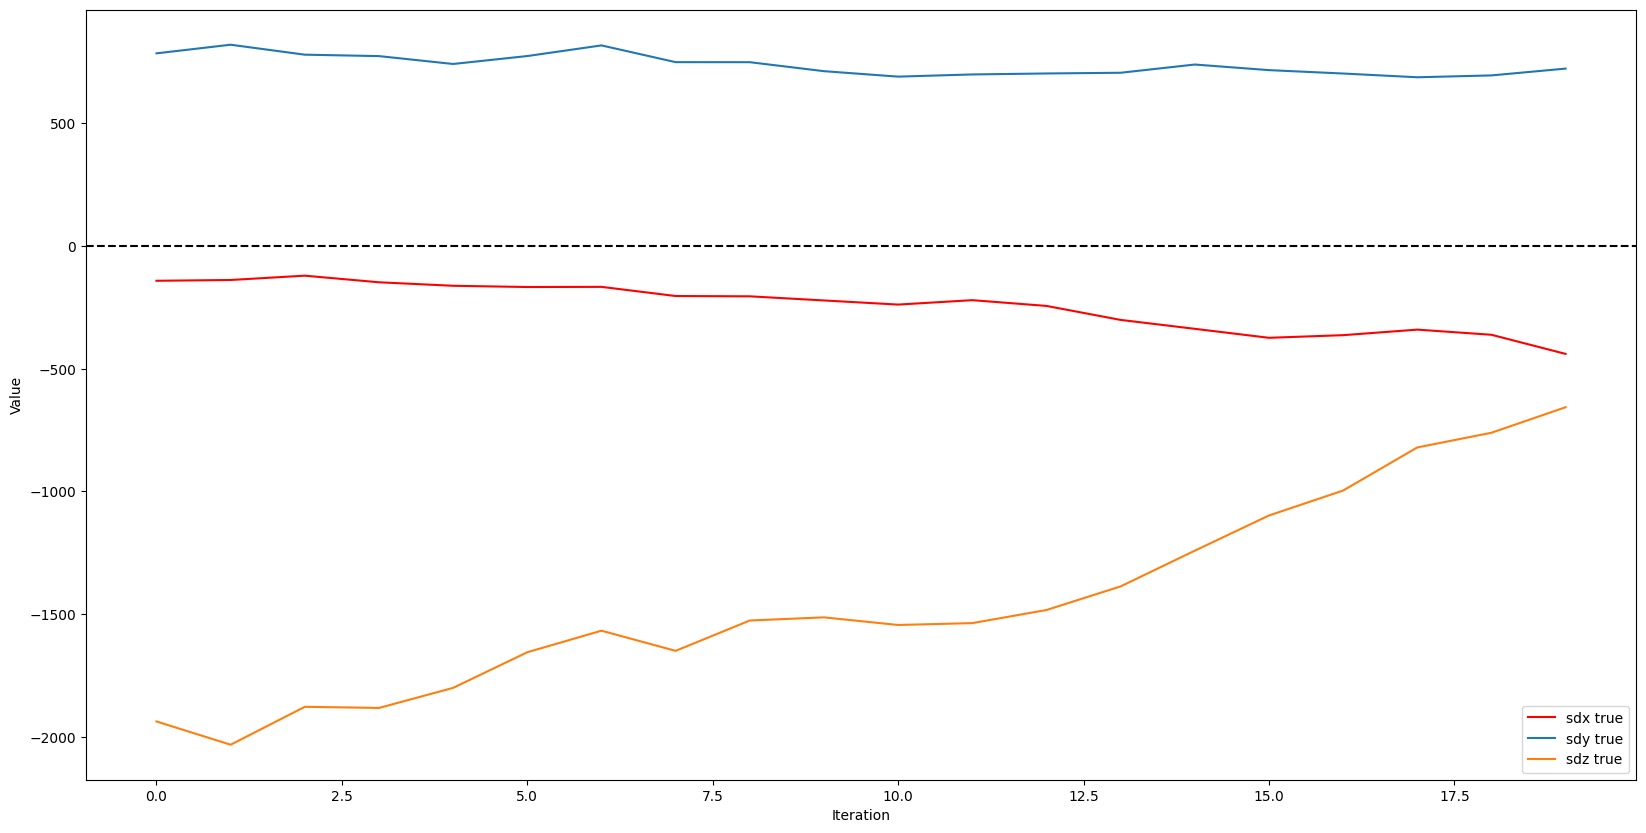

In [370]:
plt.plot(y, xt[:,0], color='red', label='sdx true')
plt.plot(y, xt[:,1], label='sdy true')
plt.plot(y, xt[:,2], label='sdz true')
#plt.plot(y, xp, color='blue', label='sdy predicted')
plt.xlabel('Iteration')
plt.ylabel('Value')
plt.axhline(0, color='black', linestyle='--')
plt.legend()

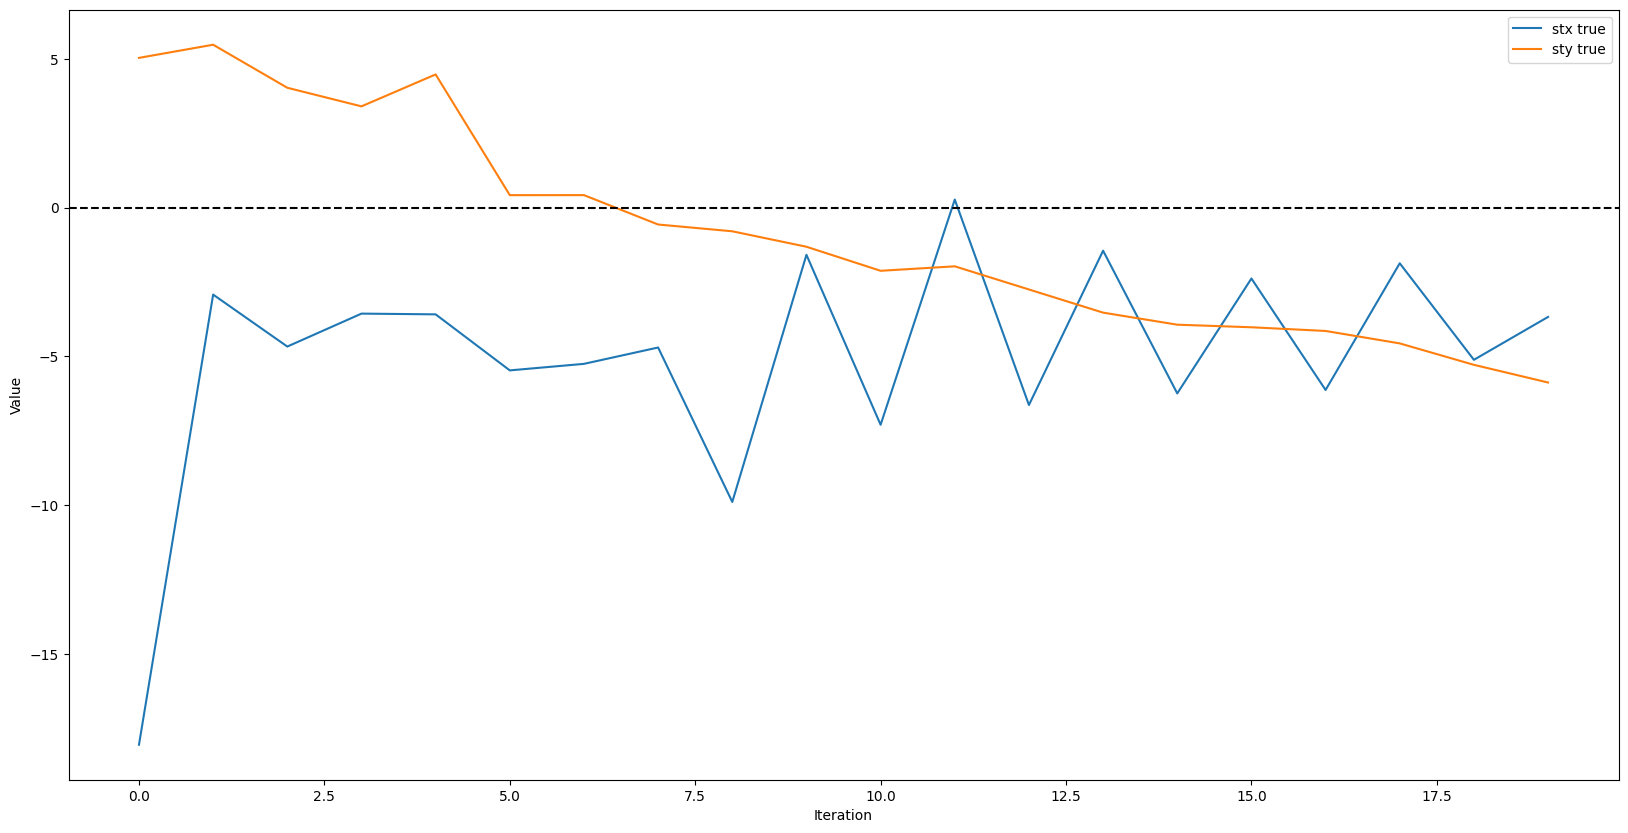

In [371]:
plt.plot(y, xt[:,3], label='stx true')
plt.plot(y, xt[:,4], label='sty true')
#plt.plot(y, xp, color='blue', label='sdy predicted')
plt.xlabel('Iteration')
plt.ylabel('Value')
plt.axhline(0, color='black', linestyle='--')
plt.legend()

In [63]:
#Truth

sdx_true = -94.52 + 37.33 + 1.19
sdy_true = -49.02 + 17.07 + 27.03
sdz_true =  25.21 - 30.98 - 12.13
stx_true =  0.09 - 0.22 + 0.15
sty_true = -0.09 - 0.16 - 0.07

## PSF 
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=10)
ct50 = genpsf(WL=0.55, sdx=sdx_true+50, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=10)

In [64]:
ct - ct50

tensor([ 4.1430, -1.0857,  2.9814,  1.4026,  0.9136, -6.2776,  2.2285,  0.1688,
        -2.4532, -1.2697])

In [137]:
C = torch.tensor([[ 2.8691e+01,  4.5176e+00, -2.0929e+01, -1.7507e+00,  8.0681e+00,
         -4.1629e-01,  1.7774e+00,  9.9978e+00,  2.4038e-01, -5.0263e-01],
        [ 4.5176e+00,  1.4418e+02, -5.0605e+00,  6.8465e+00,  1.0831e+02,
          2.1301e+01,  7.4052e-01,  9.3728e+01,  1.3421e+01,  4.7215e-01],
        [-2.0929e+01, -5.0605e+00,  2.7023e+01,  3.5139e+00, -6.6347e+00,
         -2.0786e+01,  6.0076e+00, -1.0545e+01, -1.0667e+01, -2.6511e+00],
        [-1.7507e+00,  6.8465e+00,  3.5139e+00,  1.9279e+00,  4.8626e+00,
          1.0636e-01,  1.0682e+00,  3.6921e+00,  5.2853e-01, -1.2251e-01],
        [ 8.0681e+00,  1.0831e+02, -6.6347e+00,  4.8626e+00,  9.1093e+01,
          1.4059e+01,  1.9131e+00,  7.6048e+01,  1.0410e+01, -8.2445e+00],
        [-4.1629e-01,  2.1301e+01, -2.0786e+01,  1.0636e-01,  1.4059e+01,
          5.4195e+01, -1.6168e+01,  1.8253e+01,  3.0201e+01,  8.3600e+00],
        [ 1.7774e+00,  7.4052e-01,  6.0076e+00,  1.0682e+00,  1.9131e+00,
         -1.6168e+01,  6.1435e+00, -5.2971e-01, -8.6395e+00, -3.3776e+00],
        [ 9.9978e+00,  9.3728e+01, -1.0545e+01,  3.6921e+00,  7.6048e+01,
          1.8253e+01, -5.2971e-01,  6.9023e+01,  1.2072e+01,  3.3223e-01],
        [ 2.4038e-01,  1.3421e+01, -1.0667e+01,  5.2853e-01,  1.0410e+01,
          3.0201e+01, -8.6395e+00,  1.2072e+01,  1.9959e+01,  3.5535e+00],
        [-5.0263e-01,  4.7215e-01, -2.6511e+00, -1.2251e-01, -8.2445e+00,
          8.3600e+00, -3.3776e+00,  3.3223e-01,  3.5535e+00,  1.3748e+01]])
Cinv = torch.linalg.inv(C).to(torch.float64)  # precision matrix
lnorm = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 2 + torch.log(torch.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    lsdx,lsdy,lsdz,lstx,lsty = theta
    ## PSF
    c = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=10)
    c50 = genpsf(WL=0.55, sdx=lsdx+50, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=10)

    return -0.5 * torch.matmul(c-ct, torch.matmul(Cinv, c-ct)) -0.5 * torch.matmul(c50-ct50, torch.matmul(Cinv, c50-ct50)) + lnorm

# prior transform
def ptform(utheta):

    usx,usy,usz,ustx,usty = utheta

    msx, ssx = torch.tensor(0), torch.tensor(50)  # mean and standard deviation
    lsx, hsx = torch.tensor(-130), torch.tensor(130)  # lower and upper bounds
    xsx = truncnorm(min=lsx, max=hsx, loc=msx, scale=ssx).icdf(torch.tensor(usx))

    msy, ssy = torch.tensor(0), torch.tensor(50)  # mean and standard deviation
    lsy, hsy = torch.tensor(-130), torch.tensor(130)  # lower and upper bounds
    xsy = truncnorm(min=lsy, max=hsy, loc=msy, scale=ssy).icdf(torch.tensor(usy))

    msz, ssz = torch.tensor(0), torch.tensor(350)  # mean and standard deviation
    lsz, hsz = torch.tensor(-700), torch.tensor(700)  # lower and upper bounds
    xsz = truncnorm(min=lsz, max=hsz, loc=msz, scale=ssz).icdf(torch.tensor(usz))

    mstx, sstx = torch.tensor(0), torch.tensor(0.35)  # mean and standard deviation
    lstx, hstx = torch.tensor(-0.7), torch.tensor(0.7)  # lower and upper bounds
    xstx = truncnorm(min=lstx, max=hstx, loc=mstx, scale=sstx).icdf(torch.tensor(ustx))

    msty, ssty = torch.tensor(0), torch.tensor(0.35)  # mean and standard deviation
    lsty, hsty = torch.tensor(-0.7), torch.tensor(0.7)  # lower and upper bounds
    xsty = truncnorm(min=lsty, max=hsty, loc=msty, scale=ssty).icdf(torch.tensor(usty))

    return xsx,xsy,xsz,xstx,xsty

In [85]:
dps, ls = Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=5, K = 500, iter=2000)

100%|██████████| 500/500 [00:33<00:00, 14.86it/s]
2499it [33:57,  1.23it/s, dlogz=tensor(0.0007)]                 


In [86]:
dps = np.array(dps)
ls = np.array(ls)

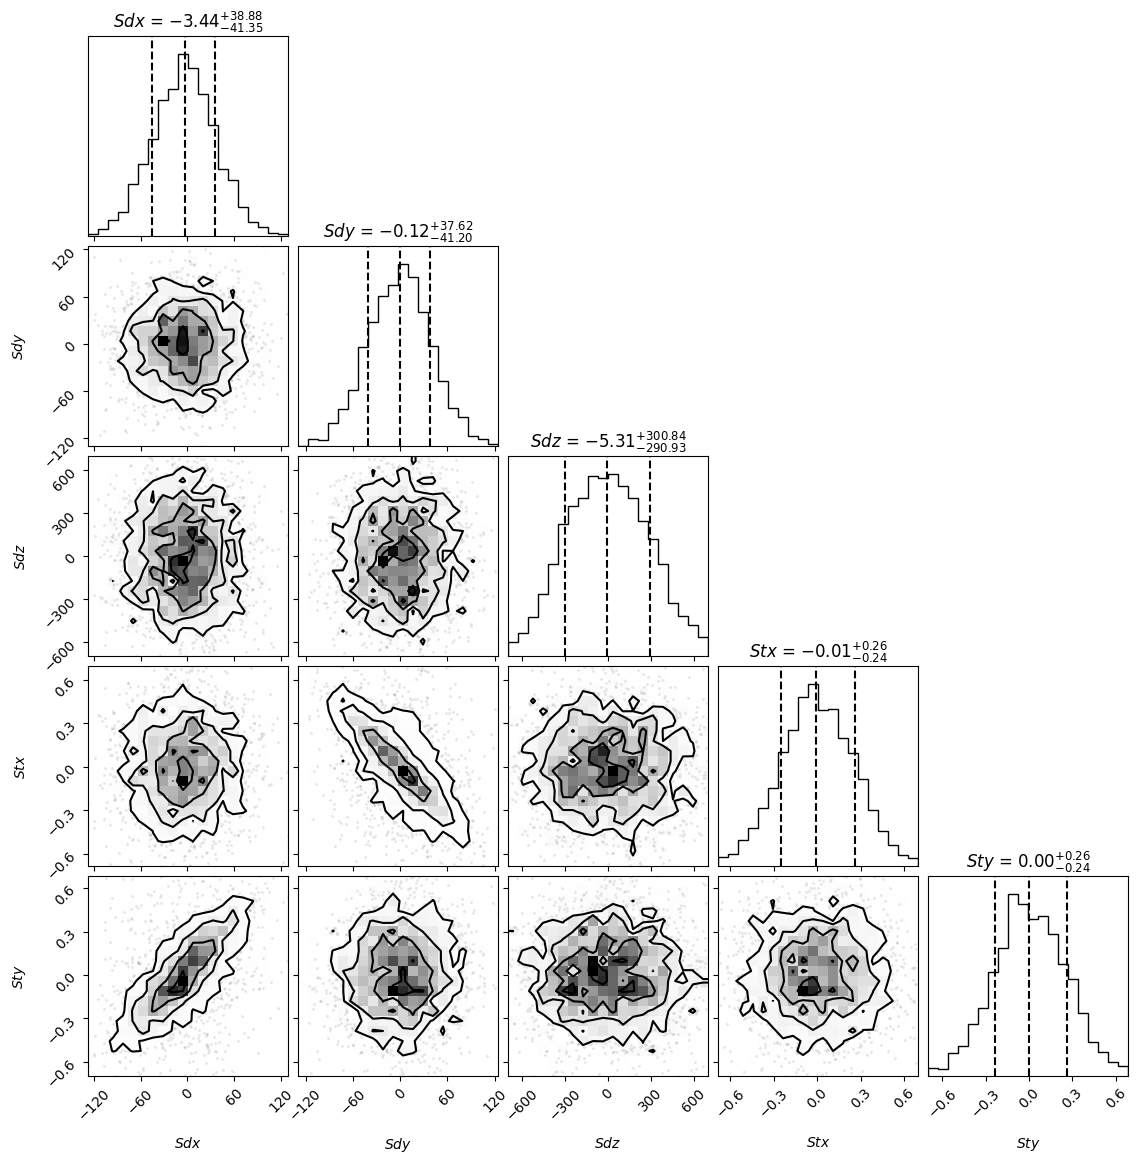

In [87]:
figure = corner.corner(
    dps,
    labels=[
        r"$Sdx$",
        r"$Sdy$",
        r"$Sdz$",
        r"$Stx$",
        r"$Sty$",
    ],
    quantiles=[0.16, 0.5, 0.84],
    weights = (ls - ls.min())/(ls.max() - ls.min()),
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [12]:
import dynesty
import dynesty.pool as dypool
import multiprocess, dill
dill.settings['recurse'] = True
dypool.mp = multiprocess

In [ ]:
dsampler = dynesty.DynamicNestedSampler(loglike, ptform, ndim=5, 
                                  sample='slice', bound='multi')
dsampler.run_nested(maxiter=2000)
dres = dsampler.results

0it [00:00, ?it/s]

10366it [7:25:00,  2.58s/it, batch: 6 | bound: 0 | nc: 1 | ncall: 502700 | eff(%):  2.042 | loglstar: -13.358 < -8.354 < -12.690 | logz: -12.564 +/-  0.051 | stop:    nan]          


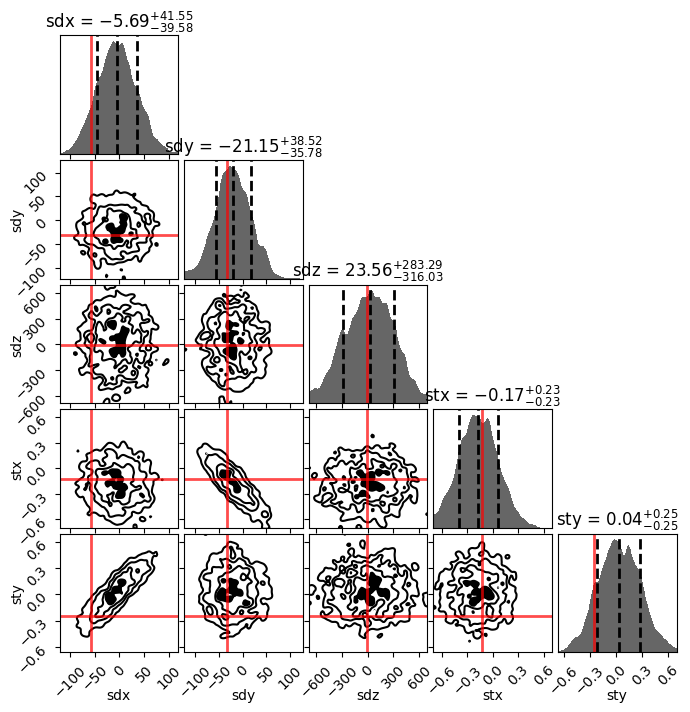

In [109]:
from dynesty import plotting as dyplot
plt.rcParams['text.usetex'] = False

labels = [r'sdx',r'sdy',r'sdz',r'stx',r'sty']
truths = [sdx_true,sdy_true,sdz_true,stx_true,sty_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1., 1., 1., 1.] , quantiles=(0.16, 0.5, 0.84), title_quantiles=(0.16, 0.5, 0.84),
                              fig=plt.subplots(5, 5, figsize=(7, 7)))

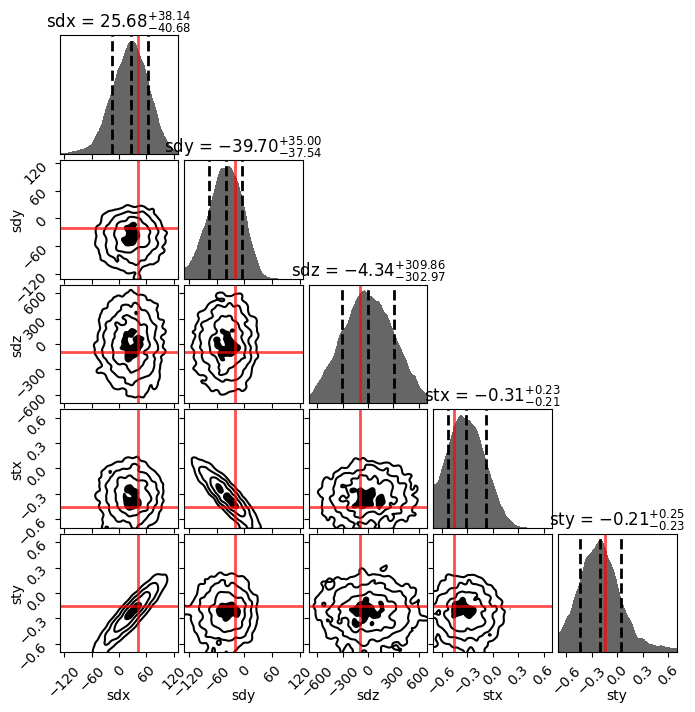

In [14]:
from dynesty import plotting as dyplot
plt.rcParams['text.usetex'] = False

labels = [r'sdx',r'sdy',r'sdz',r'stx',r'sty']
truths = [sdx_true,sdy_true,sdz_true,stx_true,sty_true]

fig, axes = dyplot.cornerplot(dres, truths=truths, show_titles=True, 
                               labels=labels, span = [1., 1., 1., 1., 1.] , quantiles=(0.16, 0.5, 0.84), title_quantiles=(0.16, 0.5, 0.84),
                              fig=plt.subplots(5, 5, figsize=(7, 7)))

In [25]:
np.median(dres['samples'][10000:][0])

np.float64(0.2523538839360823)

In [216]:
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)

In [219]:
lstep([sdx_true, sdy_true, sdz_true, stx_true, sty_true])

np.float64(0.0)

In [490]:
def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], sdz=t[2], stx=t[3], sty=t[4], dterms=15))**2)

In [220]:
from scipy.optimize import minimize

In [221]:
minimize(lstep, [0,0,0,0,0])

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 2.991151256366666e-07
        x: [ 2.097e-04 -8.709e-04 -7.946e-04  3.105e-04 -2.527e-04]
      nit: 30
      jac: [ 1.565e-04  2.499e-04  9.174e-05  1.552e-03  1.607e-04]
 hess_inv: [[ 3.676e-05  2.184e-05 ...  6.586e-06 -1.930e-05]
            [ 2.184e-05  1.400e-05 ...  4.221e-06 -1.272e-05]
            ...
            [ 6.586e-06  4.221e-06 ...  1.906e-06 -4.044e-06]
            [-1.930e-05 -1.272e-05 ... -4.044e-06  1.232e-05]]
     nfev: 769
     njev: 125

In [ ]:
#dps = [i.numpy() for i in dps]
#dps = np.array(dps)
x1 = dres['samples'][:,0]
x2 = dres['samples'][:,0]
x3 = dres['samples'][:,0]

bounds = [(-0.1, 0.1), (-0.1, 0.1), (-0.1, 0.1), (-0.1, 0.1), (-0.1, 0.1)]
result = differential_evolution(lstep, bounds, tol=0.001, disp=True, maxiter=1000)
print(result.x)
print(sdx_true, sdy_true, sdz_true)

differential_evolution step 1: f(x)= 10.654323798472474
differential_evolution step 2: f(x)= 10.654323798472474
differential_evolution step 3: f(x)= 4.8877061471992125
differential_evolution step 4: f(x)= 4.8877061471992125
differential_evolution step 5: f(x)= 4.8877061471992125
differential_evolution step 6: f(x)= 4.8877061471992125
differential_evolution step 7: f(x)= 4.477057666849036
differential_evolution step 8: f(x)= 4.477057666849036
differential_evolution step 9: f(x)= 4.477057666849036
differential_evolution step 10: f(x)= 4.477057666849036
differential_evolution step 11: f(x)= 4.477057666849036
differential_evolution step 12: f(x)= 4.477057666849036
differential_evolution step 13: f(x)= 4.1847133373265235
differential_evolution step 14: f(x)= 3.8109093914484493
differential_evolution step 15: f(x)= 3.8109093914484493
differential_evolution step 16: f(x)= 3.8109093914484493
differential_evolution step 17: f(x)= 3.8109093914484493
differential_evolution step 18: f(x)= 3.810909

In [259]:
bounds

[(array(-927.6605586), array(818.39733233)),
 (array(-927.6605586), array(818.39733233)),
 (array(-927.6605586), array(818.39733233))]

In [252]:
from scipy.optimize import dual_annealing

In [253]:
bounds = [(43.6-5.81, 43.6+5.18),(29.81-6.94, 29.81+8.03)]
result = dual_annealing(lstep, bounds)
print(result.x)
print(sdx_true, sdy_true)

[48.78       36.59916666]
43.35 31.03


In [247]:
t0 = [43.6, 29.81]
    
res = minimize(lstep, t0, method='Nelder-Mead', tol = 1e-20, options={'disp': True})
print(np.round(res.x, 3))

[51.233 36.67 ]


In [253]:
from optiland.wavefront import OPD
wf = OPD(hubble(), field=(0, 0), wavelength=0.55)

In [85]:
import optiland

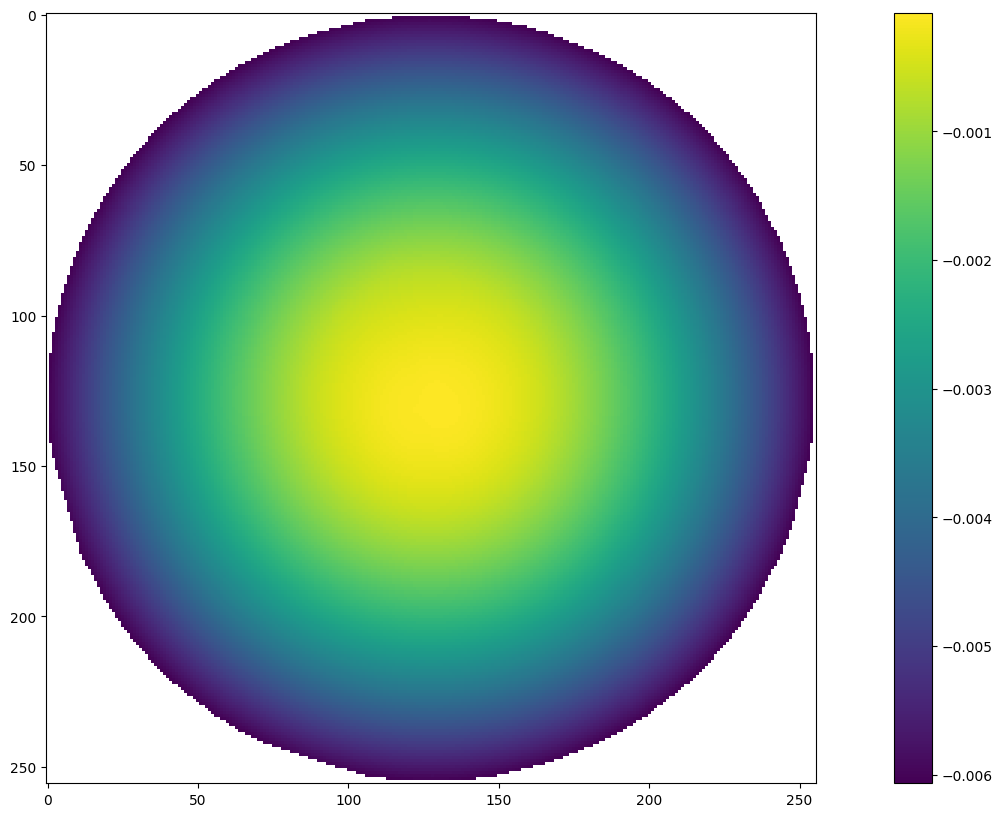

In [262]:
plt.imshow(wavefront.OPD(hubble(), field=(0,0), wavelength=0.55).generate_opd_map()['z'])
plt.colorbar()

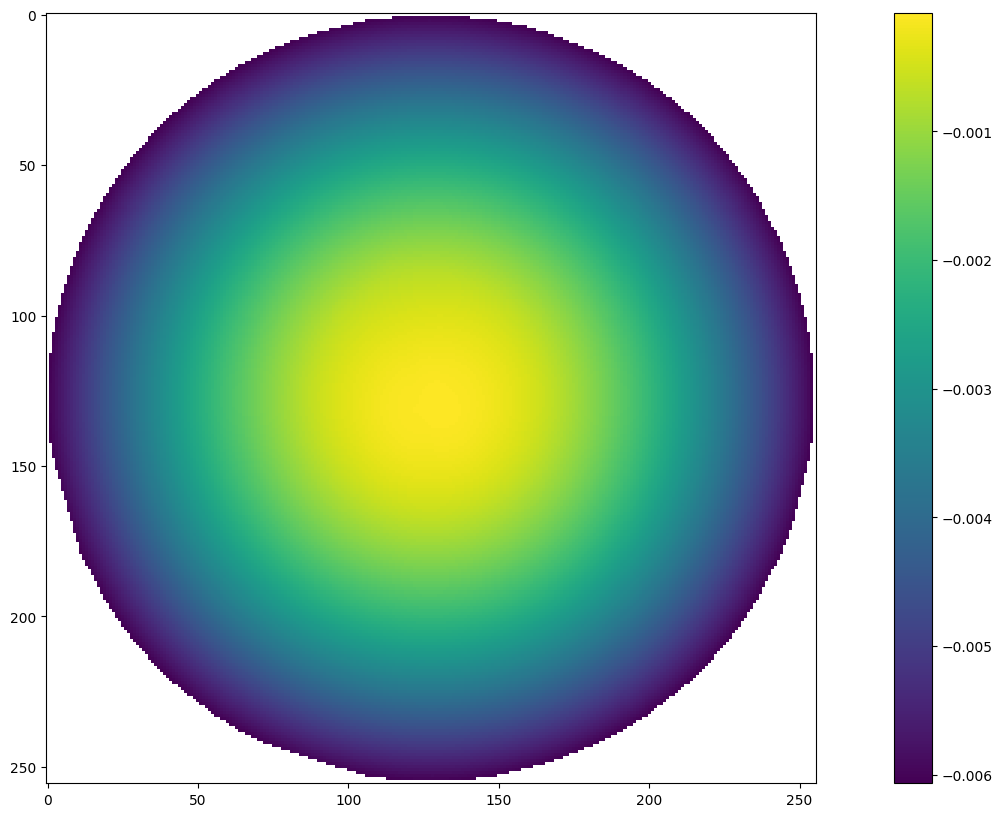

In [255]:
plt.imshow(OPD(hubble(), field=(0, 0), wavelength=0.55).generate_opd_map()['z'])
plt.colorbar()

In [256]:
np.nanstd(OPD(hubble(sdx=53.35, sdy=31.03), field=(0, 0), wavelength=0.55).generate_opd_map()['z']-OPD(hubble(sdx=52.85588418, sdy=39.8716419), field=(0, 0), wavelength=0.55).generate_opd_map()['z'])

np.float64(0.014363457186501144)

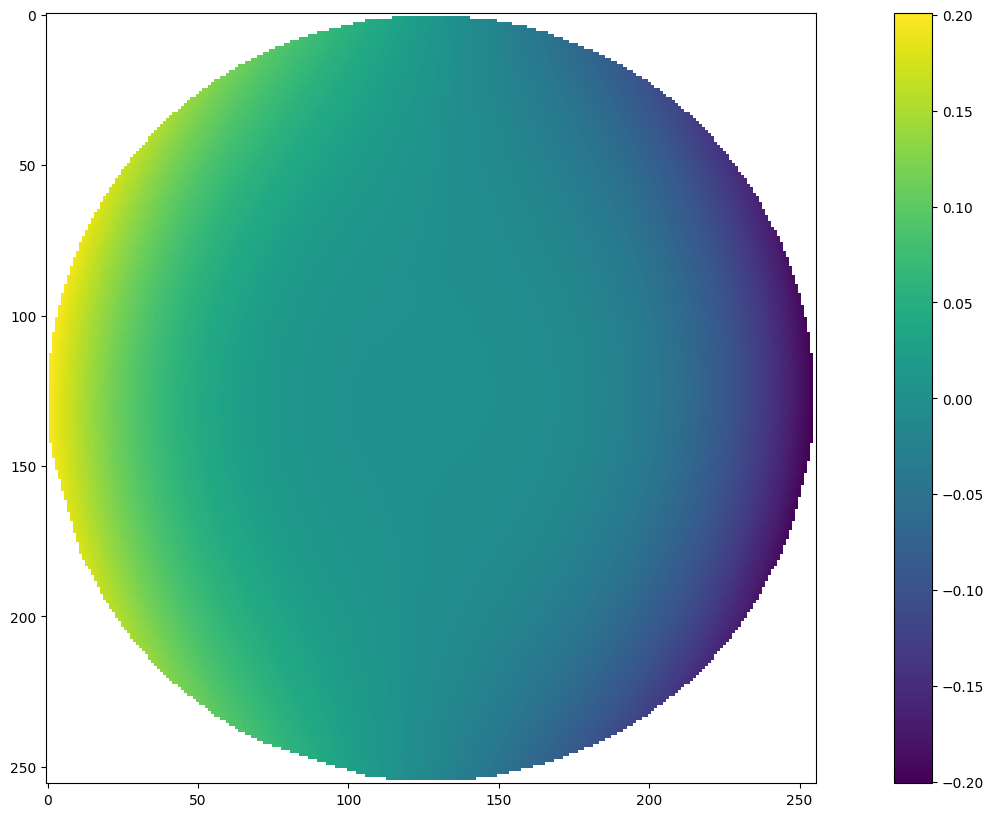

In [259]:
plt.imshow(OPD(hubble(sdx=43.76, sdy=3.16), field=(0, 0), wavelength=0.55).generate_opd_map()['z']-OPD(hubble(sdx=-0.024490283032100105, sdy=0.047881585813756435), field=(0, 0), wavelength=0.55).generate_opd_map()['z'])
plt.colorbar()

In [498]:
pts = np.array([[-18.96,-8.54,-20.08,-7.01],
 [6.21,16.66,4.33,18.4],
 [-17.42,3.27,-19.31,4.71],
 [-11.52,17.14,-13.2,19.2],
 [-2.04,3.36,-3.16,5.26],
 [-4.14,-2.79,-6.03,-0.95],
 [4.16,-6.53,2.77,-4.9],
 [4.31,20.6,1.82,22.13],
 [5.72,13.39,4.36,14.98],
 [3.24,-4.24,1.43,-2.58],
 [-0.98,-5.55,-2.87,-3.36],
 [4.86,-3.29,3.27,-1.5],
 [13.29,16.35,11.37,18.04],
 [17.94,4.11,16.67,5.94]])

Text(0.5, 1.0, 'Despace x vs. absolute error with Tx=Ty=0.01')

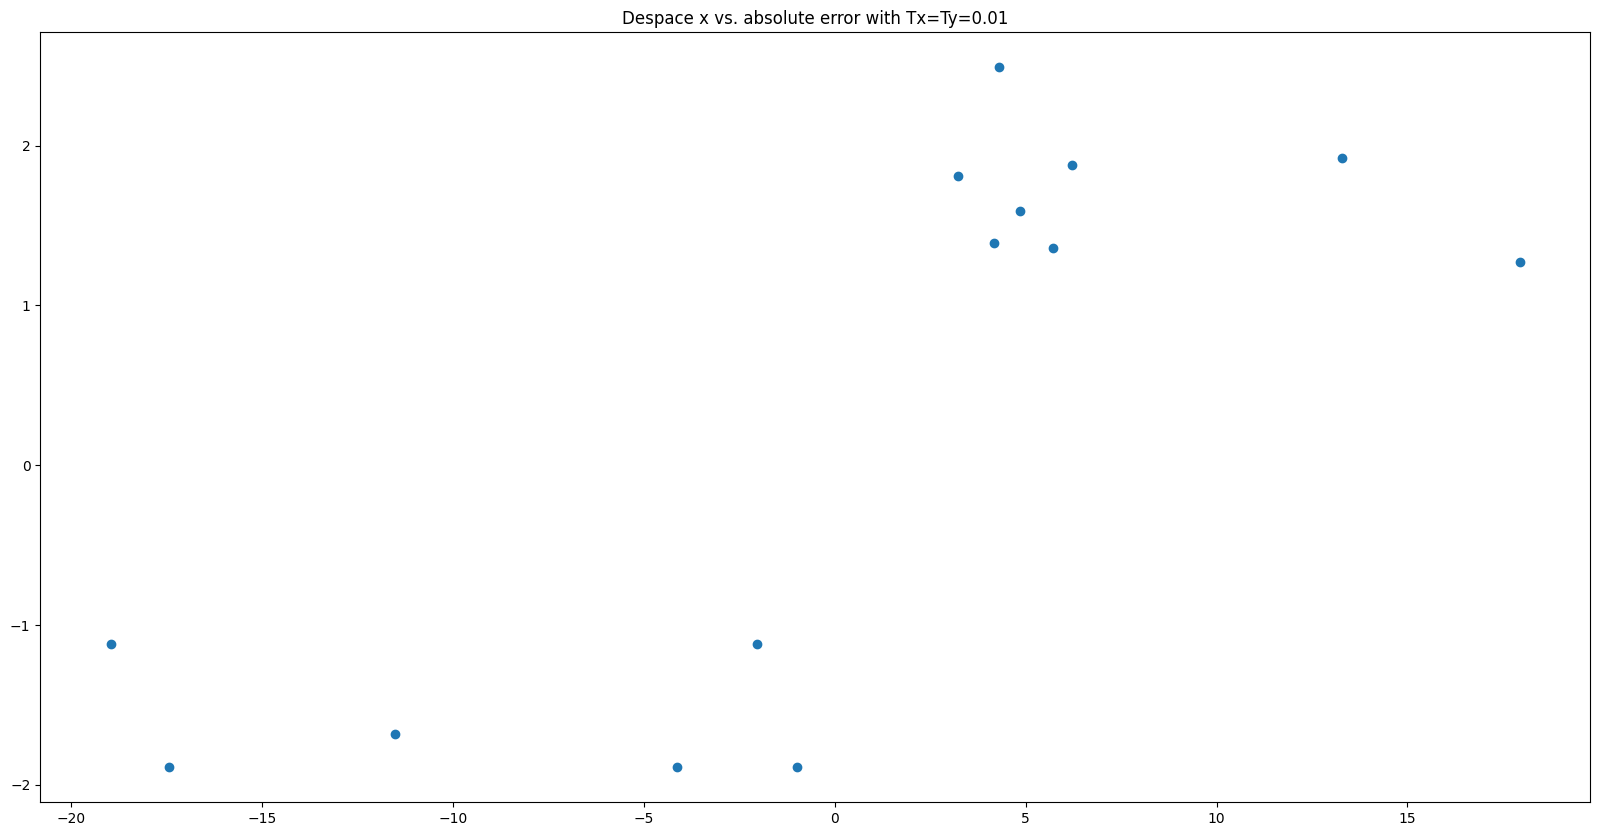

In [499]:
plt.scatter(pts[0:,0:1],(np.abs(pts[0:,0:1]))-(np.abs(pts[0:,2:3])))
plt.title("Despace x vs. absolute error with Tx=Ty=0.01")

Text(0.5, 1.0, 'Despace y vs. absolute error with Tx=Ty=0.01')

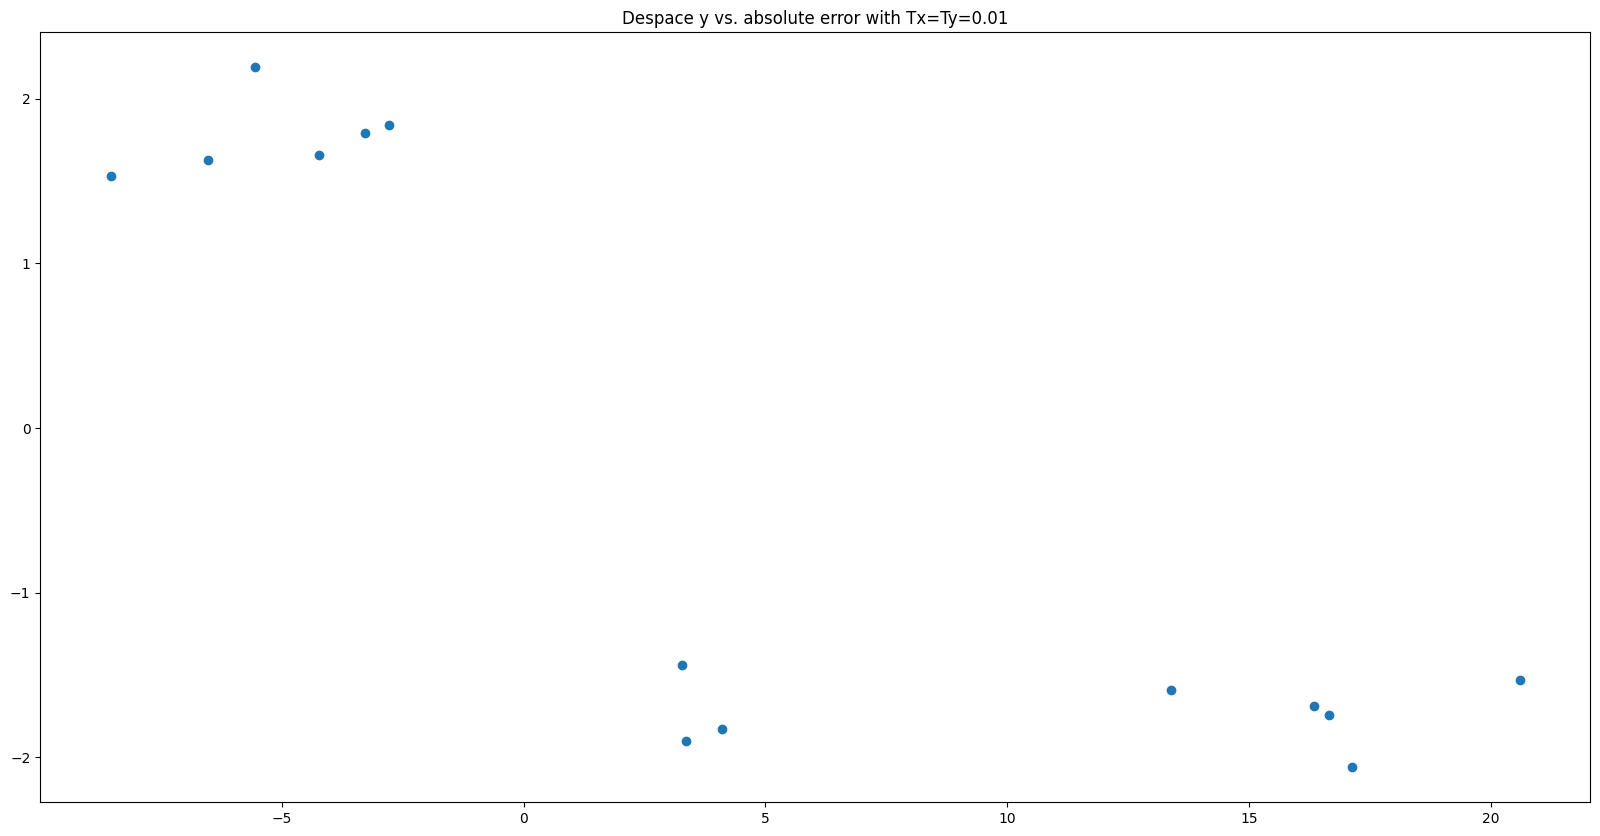

In [500]:
plt.scatter(pts[0:,1:2],(np.abs(pts[0:,1:2]))-(np.abs(pts[0:,3:4])))
plt.title("Despace y vs. absolute error with Tx=Ty=0.01")

In [572]:
pts = np.array([[-3.45,-3.87,-3.54,-3.44],
                [0.76,10.11,0.7,9.83],
                [4.02,-7.93,4.12,-8.34],
                [-5.23,-15.2,-5.38,-15.21],
                [19.94,6.54,20.18,6.15],
                [14.39,-0.93,14.64,-1.75],
                [4.1,-3.59,4.45,-4.11],
                [-1.65,13.52,-2.1,13.41],
                [0.68,-10.23,0.15,-9.9],
                [-12.52,-0.02,-12.7,0.28]])

Text(0.5, 1.0, 'Despace x vs. absolute error with Tx=0.01,Ty=0')

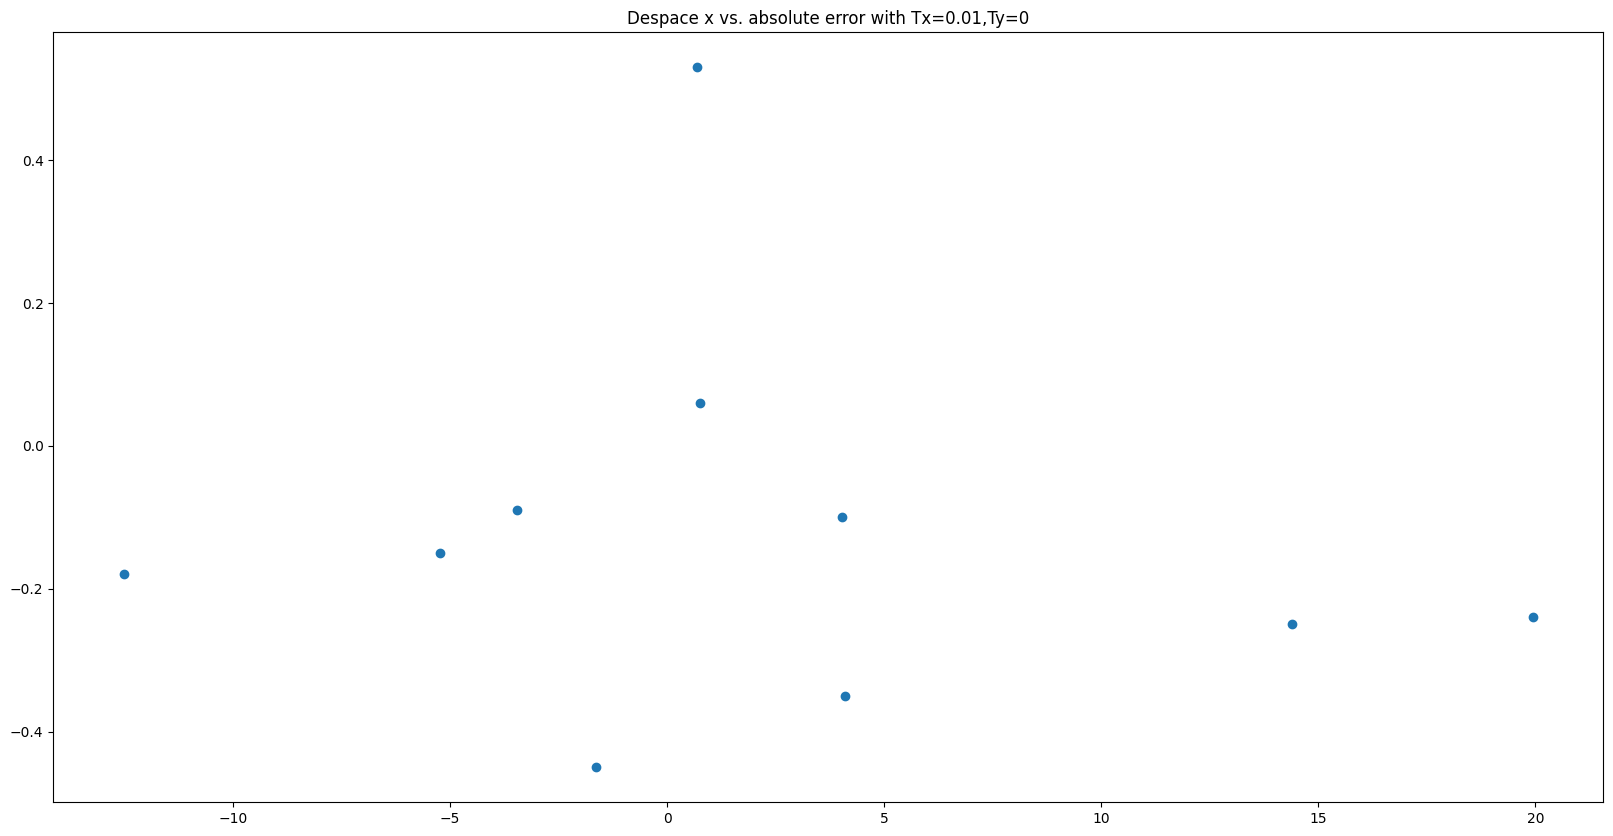

In [573]:
plt.scatter(pts[0:,0:1],(np.abs(pts[0:,0:1]))-(np.abs(pts[0:,2:3])))
plt.title("Despace x vs. absolute error with Tx=0.01,Ty=0")

Text(0.5, 1.0, 'Despace y vs. absolute error with Tx=0.01,Ty=0')

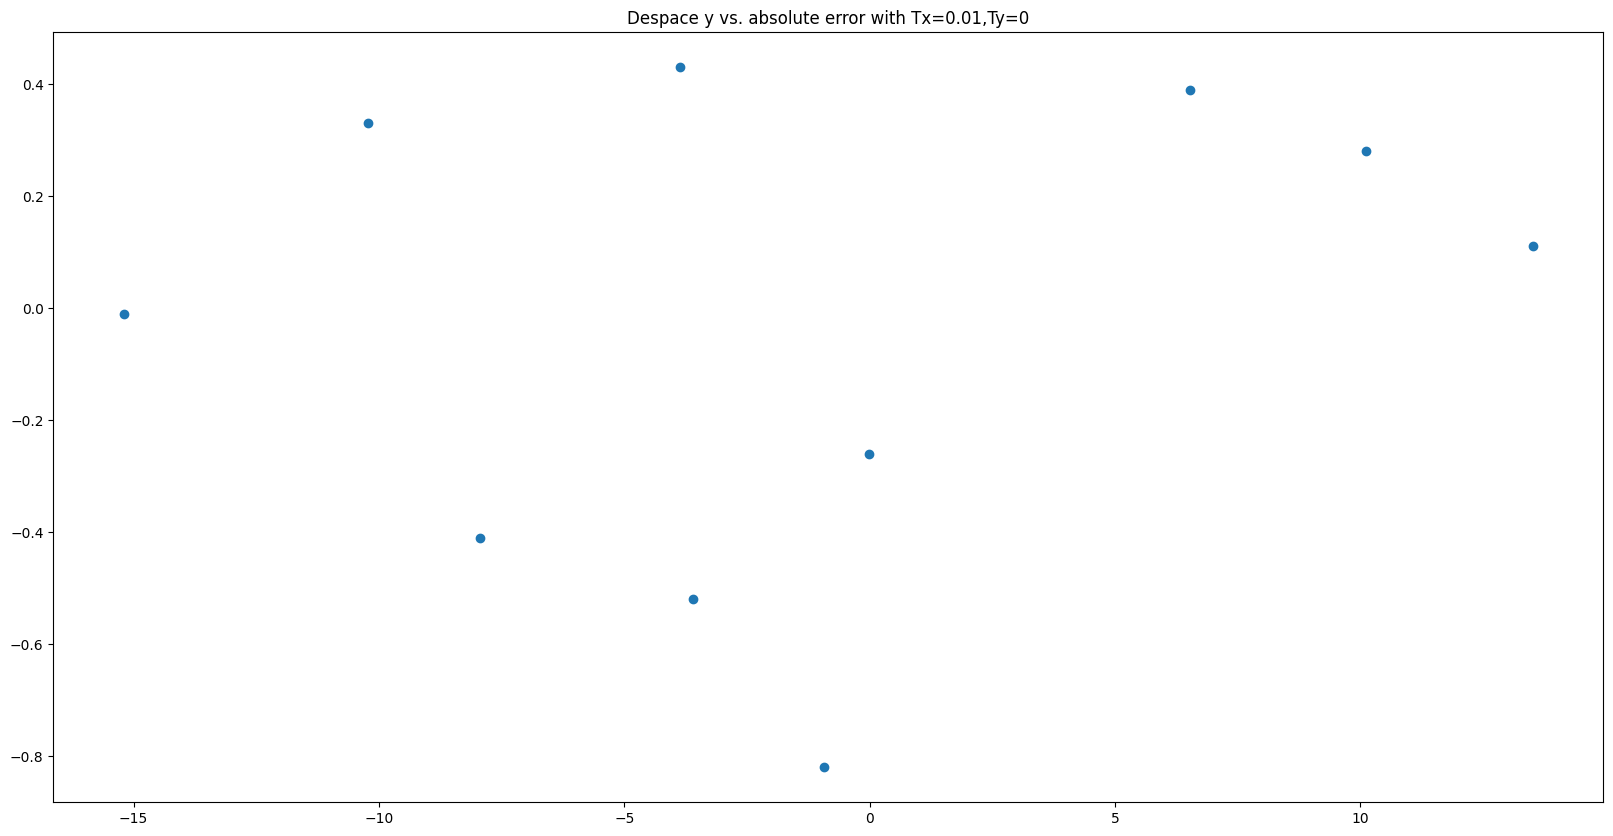

In [575]:
plt.scatter(pts[0:,1:2],(np.abs(pts[0:,1:2]))-(np.abs(pts[0:,3:4])))
plt.title("Despace y vs. absolute error with Tx=0.01,Ty=0")